# Quantum-Enhanced Variational Monte Carlo (QE-VMC) — Revised Experimental Study



## 0. Installation
Run once. Tested with Python 3.10–3.13, PennyLane 0.45, NetKet 3.23, JAX 0.12.

In [ ]:
%pip install --upgrade jax jaxlib flax netket optax pennylane

## 1. Imports and global configuration
All hyper-parameters live here. `QUICK = True` shrinks every experiment for a fast end-to-end check.

In [ ]:
import os, time, json, pickle, platform, warnings
import numpy as np
import pandas as pd
import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
import optax
import netket as nk
import pennylane as qml
from scipy import stats
import matplotlib
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

QUICK = False            # True → fast smoke test (few seeds / iterations)
FORCE_RERUN = False      # True → ignore cached results in results/data

# ── output folders ───────────────────────────────────────────────────────────
RESULTS_DIR = "results"
FIG_DIR  = os.path.join(RESULTS_DIR, "figures")
DATA_DIR = os.path.join(RESULTS_DIR, "data")
TAB_DIR  = os.path.join(RESULTS_DIR, "tables")
for d in (FIG_DIR, DATA_DIR, TAB_DIR):
    os.makedirs(d, exist_ok=True)

# ── statistics ───────────────────────────────────────────────────────────────
N_SEEDS = 2 if QUICK else 10
SEEDS   = list(range(N_SEEDS))

# ── VQE ──────────────────────────────────────────────────────────────────────
CIRCUIT_DEPTHS = [1, 2] if QUICK else [1, 2, 3]
DEPTHS_OVERRIDE = {"H4": [1, 2]}  # 8-qubit noisy simulation is the bottleneck
depths_for = lambda mol: [d for d in DEPTHS_OVERRIDE.get(mol, CIRCUIT_DEPTHS) if d in CIRCUIT_DEPTHS]
VQE_STEPS      = 40 if QUICK else 150
VQE_LR         = 0.05
N_SHOTS        = 4096          # shots for the measurement-based initialisation
SHOTS_PER_CIRCUIT = 1000       # used only for the hardware-cost estimate
ZNE_SCALES     = [1.0, 2.0, 3.0]

# ── VMC (NetKet) ─────────────────────────────────────────────────────────────
VMC_ITERS      = 60 if QUICK else 400
VMC_SAMPLES    = 1024
N_CHAINS       = 16
N_DISCARD      = 16
VMC_LR         = 0.05          # SGD step size used together with SR
SR_DIAG_SHIFT  = 1e-3
ADAM_LR        = 1e-2          # used only in the "no SR" ablation / baseline
FINAL_SAMPLES  = 16384         # samples for the final Monte-Carlo estimate
SAMPLER        = "exact"       # "exact": i.i.d. samples from |ψ|²; "metropolis": exchange MCMC
RBM_ALPHA      = 1

# ── RBM pretraining on the VQE state ─────────────────────────────────────────
PRETRAIN_STEPS = 150 if QUICK else 600
PRETRAIN_LR    = 1e-2
W_MAX          = 3.0           # clipping bound (real and imaginary parts)
PRETRAIN_LOSS  = "logres"      # "logres" (amplitude-weighted log residual) or "fidelity" (−log F)

# ── accuracy thresholds ──────────────────────────────────────────────────────
CHEM_ACC       = 1.6e-3        # chemical accuracy: 1 kcal/mol ≈ 1.6 mHa
LOOSE_THR      = 1.0e-2        # 10 mHa, secondary convergence threshold
CATASTROPHIC   = 1.0e-1        # ΔE > 100 mHa → catastrophic failure

# ── which experiment blocks to run ───────────────────────────────────────────
RUN_MAIN, RUN_BASELINES, RUN_ABLATION, RUN_DISSOCIATION = True, True, True, True
ABLATION_DEPTH, ABLATION_NOISE = 2, "HW"

CONFIG = {k: v for k, v in globals().items()
          if k.isupper() and isinstance(v, (int, float, str, bool, list))}
with open(os.path.join(RESULTS_DIR, "config.json"), "w") as f:
    json.dump(CONFIG, f, indent=2)

print(f"QUICK={QUICK} | seeds={N_SEEDS} | depths={CIRCUIT_DEPTHS} | VMC iters={VMC_ITERS}")

QUICK=False | seeds=10 | depths=[1, 2, 3] | VMC iters=400


## 2. Molecular systems
Hamiltonians are built from first principles with PennyLane's differentiable Hartree–Fock (STO-3G, Jordan–Wigner). The constant term includes nuclear repulsion, so all energies are total energies in Hartree.

* **H₂** at 0.74 Å — 4 qubits (the original benchmark)
* **LiH** at 1.595 Å, active space (2e, 3o) — 6 qubits
* **H₄** linear chain, 1.0 Å spacing — 8 qubits, strongly correlated

Note: for LiH (2e, 3o) the correlation energy (≈ 1.05 mHa) is below chemical accuracy, so Hartree–Fock is already "chemically accurate". For this molecule the percentage of correlation energy recovered is the more informative metric, and it is reported in all summaries.

In [ ]:
ANG2BOHR = 1.0 / 0.529177210903

MOLECULES = {
    "H2":  dict(symbols=["H", "H"], coords=[[0, 0, 0], [0, 0, 0.74]],
                active_electrons=None, active_orbitals=None, n_electrons=2),
    "LiH": dict(symbols=["Li", "H"], coords=[[0, 0, 0], [0, 0, 1.595]],
                active_electrons=2, active_orbitals=3, n_electrons=2),
    "H4":  dict(symbols=["H"] * 4, coords=[[0, 0, 0], [0, 0, 1.0], [0, 0, 2.0], [0, 0, 3.0]],
                active_electrons=None, active_orbitals=None, n_electrons=4),
}
MOL_NAMES = list(MOLECULES)
MOL_LABEL = {"H2": "H$_2$", "LiH": "LiH", "H4": "H$_4$"}


def build_problem(name, spec):
    """Qubit Hamiltonian (PennyLane) + matching NetKet operator in the N-electron sector."""
    mol = qml.qchem.Molecule(spec["symbols"], np.array(spec["coords"], float) * ANG2BOHR,
                             basis_name="sto-3g")
    H_pl, n = qml.qchem.molecular_hamiltonian(
        mol, method="dhf",
        active_electrons=spec["active_electrons"], active_orbitals=spec["active_orbitals"])
    ne = spec["n_electrons"]
    H_full = np.asarray(H_pl.sparse_matrix(wire_order=range(n)).toarray())

    # Pauli strings → NetKet (site i ↔ PennyLane wire i)
    labels, coeffs = [], []
    for word, c in qml.pauli.pauli_sentence(H_pl).items():
        s = ["I"] * n
        for w, p in word.items():
            s[w] = p
        labels.append("".join(s)); coeffs.append(float(np.real(c)))

    hi = nk.hilbert.Fock(n_max=1, N=n, n_particles=ne)        # particle-number conserving
    H_nk = nk.operator.PauliStrings(hi, labels, coeffs)
    states = np.asarray(hi.all_states()).astype(int)
    idx = states @ (2 ** np.arange(n - 1, -1, -1))             # basis index (wire 0 = MSB)
    H_sub = H_full[np.ix_(idx, idx)]
    assert np.allclose(H_nk.to_dense(), H_sub, atol=1e-10), "PennyLane/NetKet mapping mismatch"

    evals, evecs = np.linalg.eigh(H_sub)
    hf_bits = np.array([1] * ne + [0] * (n - ne))
    hf_pos = int(np.where((states == hf_bits).all(1))[0][0])
    graph = nk.graph.Graph(edges=[(i, j) for i in range(n) for j in range(i + 1, n)])

    try:
        n_groups = len(qml.pauli.group_observables(list(H_pl.terms()[1]), grouping_type="qwc"))
    except Exception:
        n_groups = len(labels)

    return dict(name=name, n=n, ne=ne, H_pl=H_pl, H_full=H_full, H_sub=H_sub, H_nk=H_nk,
                hi=hi, states=states, idx=idx, graph=graph,
                E0=float(evals[0]), psi0=evecs[:, 0], E_HF=float(H_sub[hf_pos, hf_pos].real),
                hf_pos=hf_pos, n_terms=len(labels), n_groups=n_groups,
                E0_full=float(np.linalg.eigvalsh(H_full)[0]))


PROBLEMS = {m: build_problem(m, s) for m, s in MOLECULES.items()}

rows = []
for m, P in PROBLEMS.items():
    rows.append(dict(Molecule=m, Qubits=P["n"], Electrons=P["ne"], SectorDim=len(P["states"]),
                     PauliTerms=P["n_terms"], QWCGroups=P["n_groups"],
                     E_HF=P["E_HF"], E_exact=P["E0"],
                     E_corr_mHa=1e3 * (P["E_HF"] - P["E0"])))
mol_table = pd.DataFrame(rows)
mol_table.to_csv(os.path.join(TAB_DIR, "table_molecules.csv"), index=False)
mol_table

,Molecule,Qubits,Electrons,SectorDim,PauliTerms,QWCGroups,E_HF,E_exact,E_corr_mHa
0,H2,4,2,6,15,5,-1.116759,-1.137284,20.524527
1,LiH,6,2,15,62,17,-7.862024,-7.863078,1.053894
2,H4,8,4,70,185,68,-2.098546,-2.166387,67.841512


## 3. Ansatz, noisy-circuit simulator (JAX) and PennyLane cross-check
* **`uccsd`** (default) — particle-conserving k-UCCSD: `D` repetitions of all spin-conserving double and single excitations (Givens rotations) acting on the Hartree–Fock state. Noise is applied per CNOT-equivalent of each gate (single ≈ 2 CNOTs, double ≈ 14 CNOTs).
* **`hea`** — the hardware-efficient RY–RZ + CNOT-ladder circuit of the original manuscript, with uniform random initialisation.

Both are simulated with a small JIT-compiled density-matrix simulator (~100× faster than `default.mixed` at 8 qubits). The cross-check cell verifies it against PennyLane to machine precision.

In [ ]:
ANSATZ = "uccsd"          # "uccsd" (default) or "hea" (original manuscript circuit)
INIT_STD = 0.1            # UCCSD: initial angles ~ N(0, INIT_STD); HEA: U(-π, π)
CNOT_EQ = {"S": 2, "D": 14}

_X = np.array([[0, 1], [1, 0]], complex)
_CNOT = np.array([[1, 0, 0, 0], [0, 1, 0, 0], [0, 0, 0, 1], [0, 0, 1, 0]], complex)
RATE_KEYS = ["p1", "pcx_loc", "pcx2", "amp1", "ph1", "amp2", "ph2", "ro"]


def _ry(t):
    c, s = jnp.cos(t / 2), jnp.sin(t / 2)
    return jnp.array([[c, -s], [s, c]], dtype=complex)


def _rz(t):
    return jnp.array([[jnp.exp(-0.5j * t), 0], [0, jnp.exp(0.5j * t)]], dtype=complex)


def _single_exc(t):                                # PennyLane SingleExcitation
    c, s = jnp.cos(t / 2), jnp.sin(t / 2)
    U = jnp.eye(4, dtype=complex)
    return U.at[1, 1].set(c).at[1, 2].set(-s).at[2, 1].set(s).at[2, 2].set(c)


def _double_exc(t):                                # PennyLane DoubleExcitation
    c, s = jnp.cos(t / 2), jnp.sin(t / 2)
    U = jnp.eye(16, dtype=complex)
    return U.at[3, 3].set(c).at[3, 12].set(-s).at[12, 3].set(s).at[12, 12].set(c)


def _apply(t, U, axes):
    k = len(axes)
    U = jnp.asarray(U).reshape((2,) * (2 * k))
    t = jnp.tensordot(U, t, axes=(list(range(k, 2 * k)), list(axes)))
    return jnp.moveaxis(t, list(range(k)), list(axes))


def _dm_u(rho, U, wires, n):                       # ρ → U ρ U†
    rho = _apply(rho, U, wires)
    return _apply(rho, jnp.conj(jnp.asarray(U)), [w + n for w in wires])


def _mix(rho, q, n):                               # ρ → I/2 ⊗ Tr_q ρ
    tr = jnp.trace(rho, axis1=q, axis2=n + q) / 2.0
    tr = jnp.expand_dims(tr, (q, n + q))
    shape = [2 if a in (q, n + q) else 1 for a in range(2 * n)]
    return tr * jnp.eye(2).reshape(shape)


def _depol1(rho, p, q, n):                         # PennyLane DepolarizingChannel convention
    return (1 - 4 * p / 3) * rho + (4 * p / 3) * _mix(rho, q, n)


def _depol2(rho, p, q1, q2, n):                    # two-qubit depolarising (15 Paulis, prob p)
    pp = 16 * p / 15
    return (1 - pp) * rho + pp * _mix(_mix(rho, q1, n), q2, n)


def _thermal(rho, ga, gp, q, n):                   # AmplitudeDamping(ga) then PhaseDamping(gp)
    r = jnp.moveaxis(rho, (q, n + q), (0, 1))
    f = jnp.sqrt(1 - ga) * jnp.sqrt(1 - gp)
    r = jnp.stack([jnp.stack([r[0, 0] + ga * r[1, 1], f * r[0, 1]]),
                   jnp.stack([f * r[1, 0], (1 - ga) * r[1, 1]])])
    return jnp.moveaxis(r, (0, 1), (q, n + q))


def _bitflip(rho, p, q, n):
    return (1 - p) * rho + p * _dm_u(rho, _X, [q], n)


# effective rates for m repeated applications of the same channel
def _rep_dep1(p, m): return 0.75 * (1 - (1 - 4 * p / 3) ** m)
def _rep_dep2(p, m): return (15 / 16) * (1 - (1 - 16 * p / 15) ** m)
def _rep_damp(g, m): return 1 - (1 - g) ** m


def excitation_gates(P):
    singles, doubles = qml.qchem.excitations(P["ne"], P["n"])
    return [("D", tuple(d)) for d in doubles] + [("S", tuple(s)) for s in singles]


def n_params_of(P, depth):
    return depth * (len(excitation_gates(P)) if ANSATZ == "uccsd" else 2 * P["n"])


def init_params(P, depth, rng):
    if ANSATZ == "uccsd":
        return rng.normal(0.0, INIT_STD, (depth, len(excitation_gates(P))))
    return rng.uniform(-np.pi, np.pi, (depth, P["n"], 2))


def _gate_noise(rho, kind, wires, r, kinds, n):
    """Noise after a UCCSD excitation gate, scaled by its CNOT-equivalent count."""
    m = CNOT_EQ[kind]
    if "pcx_loc" in kinds:                         # ε model: each CNOT hits 2 qubits
        pe = _rep_dep1(r[1], 2 * m / len(wires))
        for w in wires:
            rho = _depol1(rho, pe, w, n)
    if "pcx2" in kinds:                            # HW model: 2q depolarising per CNOT
        pairs = list(zip(wires[:-1], wires[1:]))
        pe = _rep_dep2(r[2], m / len(pairs))
        for a, b in pairs:
            rho = _depol2(rho, pe, a, b, n)
    if "p1" in kinds:
        for w in wires:
            rho = _depol1(rho, r[0], w, n)
    if "amp2" in kinds:                            # T1/T2 during the whole gate
        for w in wires:
            rho = _thermal(rho, _rep_damp(r[5], m), _rep_damp(r[6], m), w, n)
    return rho


_SIM_CACHE = {}


def get_sim(P, depth, kinds):
    """Jitted state / density / energy functions for one (molecule, depth, noise-channel set)."""
    key = (ANSATZ, P["name"], P["n"], round(P["E0"], 8), depth, kinds)
    if key in _SIM_CACHE:
        return _SIM_CACHE[key]
    n, ne = P["n"], P["ne"]
    Hj = jnp.asarray(P["H_full"])
    hf_index = int("1" * ne + "0" * (n - ne), 2)
    gates = excitation_gates(P) if ANSATZ == "uccsd" else None

    def layer_pure(psi, lp):
        if ANSATZ == "uccsd":
            for g, (kind, w) in enumerate(gates):
                psi = _apply(psi, _double_exc(lp[g]) if kind == "D" else _single_exc(lp[g]), list(w))
        else:
            for q in range(n):
                psi = _apply(psi, _ry(lp[q, 0]), [q])
                psi = _apply(psi, _rz(lp[q, 1]), [q])
            for q in range(n - 1):
                psi = _apply(psi, _CNOT, [q, q + 1])
        return psi, None

    def layer_noisy(rho, lp, r):
        if ANSATZ == "uccsd":
            for g, (kind, w) in enumerate(gates):
                rho = _dm_u(rho, _double_exc(lp[g]) if kind == "D" else _single_exc(lp[g]), list(w), n)
                rho = _gate_noise(rho, kind, list(w), r, kinds, n)
            return rho, None
        for q in range(n):
            rho = _dm_u(rho, _ry(lp[q, 0]), [q], n)
            rho = _dm_u(rho, _rz(lp[q, 1]), [q], n)
            if "p1" in kinds:
                rho = _depol1(rho, r[0], q, n)
            if "amp1" in kinds:
                rho = _thermal(rho, r[3], r[4], q, n)
        for q in range(n - 1):
            rho = _dm_u(rho, _CNOT, [q, q + 1], n)
            if "pcx_loc" in kinds:
                rho = _depol1(_depol1(rho, r[1], q, n), r[1], q + 1, n)
            if "pcx2" in kinds:
                rho = _depol2(rho, r[2], q, q + 1, n)
            if "amp2" in kinds:
                for w in (q, q + 1):
                    rho = _thermal(rho, r[5], r[6], w, n)
        return rho, None

    def state(params):                             # layers are scanned → compile once per layer
        psi = jnp.zeros(2 ** n, complex).at[hf_index].set(1.0).reshape((2,) * n)
        psi, _ = jax.lax.scan(layer_pure, psi, params)
        return psi.reshape(-1)

    def density(params, r):
        rho = jnp.zeros((2 ** n, 2 ** n), complex).at[hf_index, hf_index].set(1.0)
        rho = rho.reshape((2,) * (2 * n))
        rho, _ = jax.lax.scan(lambda c, lp: layer_noisy(c, lp, r), rho, params)
        if "ro" in kinds:
            for q in range(n):
                rho = _bitflip(rho, r[7], q, n)
        return rho.reshape(2 ** n, 2 ** n)

    def e_pure(params):
        psi = state(params)
        return jnp.real(jnp.vdot(psi, Hj @ psi))

    def e_noisy(params, r):
        return jnp.real(jnp.sum(density(params, r) * Hj.T))

    sim = dict(state=jax.jit(state), density=jax.jit(density),
               e_pure=jax.jit(e_pure), e_noisy=jax.jit(e_noisy),
               vg_pure=jax.jit(jax.value_and_grad(e_pure)),
               vg_noisy=jax.jit(jax.value_and_grad(e_noisy)))
    _SIM_CACHE[key] = sim
    return sim

**Cross-check.** The same circuits, with every noise channel switched on, are executed in PennyLane (`default.mixed` / `default.qubit`); energies and noiseless states must agree for both ansätze.

In [ ]:
def _K2(p):
    pl = [np.eye(2), _X, np.array([[0, -1j], [1j, 0]]), np.diag([1, -1])]
    return [np.sqrt(1 - p) * np.eye(4)] + [np.sqrt(p / 15) * np.kron(a, b)
                                           for i, a in enumerate(pl) for j, b in enumerate(pl) if (i, j) != (0, 0)]


def pennylane_reference(P, depth, params, r, ansatz):
    n, ne = P["n"], P["ne"]
    hf = np.array([1] * ne + [0] * (n - ne))

    def body(noisy):
        qml.BasisState(hf, wires=range(n))
        for l in range(depth):
            if ansatz == "uccsd":
                for g, (kind, w) in enumerate(excitation_gates(P)):
                    (qml.DoubleExcitation if kind == "D" else qml.SingleExcitation)(params[l, g], wires=list(w))
                    if not noisy:
                        continue
                    m = CNOT_EQ[kind]
                    for q in w:
                        qml.DepolarizingChannel(_rep_dep1(r[1], 2 * m / len(w)), wires=q)
                    pairs = list(zip(w[:-1], w[1:]))
                    for a, b in pairs:
                        qml.QubitChannel(_K2(_rep_dep2(r[2], m / len(pairs))), wires=[a, b])
                    for q in w:
                        qml.DepolarizingChannel(r[0], wires=q)
                    for q in w:
                        qml.AmplitudeDamping(_rep_damp(r[5], m), wires=q); qml.PhaseDamping(_rep_damp(r[6], m), wires=q)
                continue
            for q in range(n):
                qml.RY(params[l, q, 0], wires=q); qml.RZ(params[l, q, 1], wires=q)
                if noisy:
                    qml.DepolarizingChannel(r[0], wires=q)
                    qml.AmplitudeDamping(r[3], wires=q); qml.PhaseDamping(r[4], wires=q)
            for q in range(n - 1):
                qml.CNOT(wires=[q, q + 1])
                if noisy:
                    qml.DepolarizingChannel(r[1], wires=q); qml.DepolarizingChannel(r[1], wires=q + 1)
                    qml.QubitChannel(_K2(r[2]), wires=[q, q + 1])
                    for w in (q, q + 1):
                        qml.AmplitudeDamping(r[5], wires=w); qml.PhaseDamping(r[6], wires=w)
        if noisy:
            for q in range(n):
                qml.BitFlip(r[7], wires=q)

    @qml.qnode(qml.device("default.mixed", wires=n))
    def noisy_circ():
        body(True); return qml.expval(P["H_pl"])

    @qml.qnode(qml.device("default.qubit", wires=n))
    def state_circ():
        body(False); return qml.state()

    return float(noisy_circ()), np.asarray(state_circ())


_saved_ansatz = ANSATZ
rng = np.random.default_rng(123)
test_rates = np.array([0.01, 0.005, 0.02, 0.003, 0.004, 0.006, 0.007, 0.02])
for ANSATZ in ["uccsd", "hea"]:
    for m in ["H2", "LiH"]:
        P = PROBLEMS[m]
        prm = init_params(P, 2, rng) * (5 if ANSATZ == "uccsd" else 1)
        sim = get_sim(P, 2, frozenset(RATE_KEYS))
        e_ours = float(sim["e_noisy"](jnp.asarray(prm), jnp.asarray(test_rates)))
        sv_ours = np.asarray(sim["state"](jnp.asarray(prm)))
        e_pl, sv_pl = pennylane_reference(P, 2, prm, test_rates, ANSATZ)
        print(f"{ANSATZ:5s} {m:4s}  E(JAX)={e_ours:.10f}  E(PennyLane)={e_pl:.10f}  "
              f"|ΔE|={abs(e_ours - e_pl):.1e}  |Δψ|={np.abs(sv_ours - sv_pl).max():.1e}")
        assert abs(e_ours - e_pl) < 1e-8 and np.abs(sv_ours - sv_pl).max() < 1e-8
ANSATZ = _saved_ansatz
print("Simulator verified against PennyLane ✔")

uccsd H2    E(JAX)=-0.3872983430  E(PennyLane)=-0.3872983430  |ΔE|=5.3e-13  |Δψ|=1.1e-16
uccsd LiH   E(JAX)=-7.3715302997  E(PennyLane)=-7.3715302997  |ΔE|=3.4e-11  |Δψ|=2.8e-17
hea   H2    E(JAX)=0.0041959124  E(PennyLane)=0.0041959124  |ΔE|=3.5e-14  |Δψ|=1.8e-16
hea   LiH   E(JAX)=-7.2131683188  E(PennyLane)=-7.2131683188  |ΔE|=1.4e-11  |Δψ|=1.4e-16
Simulator verified against PennyLane ✔


## 4. Noise models
* **ε-sweep** — the depolarising model of the original manuscript: a channel of strength ε on every qubit after each rotation layer and on both qubits after every CNOT.
* **HW** — a superconducting-device-like model with representative calibration values: thermal relaxation (T₁ = 150 µs, T₂ = 100 µs), 1q gate error 3×10⁻⁴ (50 ns), 2q depolarising error 8×10⁻³ (300 ns), and 1.5 % readout bit-flip.

In [ ]:
def synthetic(eps):
    r = dict.fromkeys(RATE_KEYS, 0.0); r["p1"] = eps; r["pcx_loc"] = eps
    return r


def hardware_like(T1=150e-6, T2=100e-6, t1q=50e-9, t2q=300e-9, p1q=3e-4, p2q=8e-3, p_ro=1.5e-2):
    Tphi = 1.0 / (1.0 / T2 - 1.0 / (2 * T1))
    r = dict.fromkeys(RATE_KEYS, 0.0)
    r.update(p1=p1q, pcx2=p2q, ro=p_ro,
             amp1=1 - np.exp(-t1q / T1), ph1=1 - np.exp(-2 * t1q / Tphi),
             amp2=1 - np.exp(-t2q / T1), ph2=1 - np.exp(-2 * t2q / Tphi))
    return r


NOISE_MODELS = {
    "ε=0":    synthetic(0.0),
    "ε=0.01": synthetic(0.01),
    "ε=0.05": synthetic(0.05),
    "ε=0.10": synthetic(0.10),
    "HW":     hardware_like(),
}
NOISE_NAMES = list(NOISE_MODELS)
if QUICK:
    NOISE_NAMES = ["ε=0", "ε=0.05", "HW"]


def rates_of(name, scale=1.0):
    r = NOISE_MODELS[name]
    return np.array([min(r[k] * scale, 0.75) for k in RATE_KEYS])


def kinds_of(name):
    r = NOISE_MODELS[name]
    k = {key for key in RATE_KEYS if r[key] > 0}
    if "amp1" in k or "ph1" in k: k |= {"amp1"}
    if "amp2" in k or "ph2" in k: k |= {"amp2"}
    return frozenset(k)


noise_table = pd.DataFrame({n: NOISE_MODELS[n] for n in NOISE_MODELS}).T
noise_table.to_csv(os.path.join(TAB_DIR, "table_noise_models.csv"))
noise_table.map(lambda v: f"{v:.2e}")

,p1,pcx_loc,pcx2,amp1,ph1,amp2,ph2,ro
ε=0,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00
ε=0.01,1.00e-02,1.00e-02,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00
ε=0.05,5.00e-02,5.00e-02,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00
ε=0.10,1.00e-01,1.00e-01,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00
HW,3.00e-04,0.00e+00,8.00e-03,3.33e-04,6.66e-04,2.00e-03,3.99e-03,1.50e-02


## 5. VQE stage
Adam optimisation of the noisy energy. From the final parameters we also compute:
* two **error-mitigation baselines**: zero-noise extrapolation (Richardson, scales 1/2/3) and symmetry verification (post-selection on electron number);
* the **initial states** handed to VMC: the noiseless state of the trained circuit (`vqe_sv`), and a measurement-only state from `N_SHOTS` noisy shots, post-selected on electron number with magnitudes only and no phases (`vqe_shots`).

In [ ]:
def run_vqe(P, depth, noise, seed):
    kinds = kinds_of(noise)
    sim = get_sim(P, depth, kinds)
    rng = np.random.default_rng(10_000 * seed + 100 * depth + 7)
    params = jnp.asarray(init_params(P, depth, rng))
    r = jnp.asarray(rates_of(noise))
    noisy = len(kinds) > 0
    vg = (lambda p: sim["vg_noisy"](p, r)) if noisy else sim["vg_pure"]

    opt = optax.adam(VQE_LR); st = opt.init(params)
    hist = []
    t0 = time.perf_counter()
    for _ in range(VQE_STEPS):
        e, g = vg(params)
        upd, st = opt.update(g, st)
        params = optax.apply_updates(params, upd)
        hist.append(float(e))
    e_final = float(sim["e_noisy"](params, r)) if noisy else float(sim["e_pure"](params))
    elapsed = time.perf_counter() - t0

    # error-mitigation baselines
    if noisy:
        es = [float(sim["e_noisy"](params, jnp.asarray(rates_of(noise, s)))) for s in ZNE_SCALES]
        e_zne = float(np.polyval(np.polyfit(ZNE_SCALES, es, len(ZNE_SCALES) - 1), 0.0))
        rho = np.asarray(sim["density"](params, r))
    else:
        psi = np.asarray(sim["state"](params)); e_zne = e_final
        rho = np.outer(psi, psi.conj())
    idx = P["idx"]
    blk = rho[np.ix_(idx, idx)]
    p_keep = float(np.real(np.trace(blk)))
    e_sym = float(np.real(np.sum(blk * P["H_sub"].T)) / p_keep)

    # initial states for VMC
    sv = np.asarray(sim["state"](params))
    sv_sub = sv[idx]
    leakage = 1.0 - float(np.sum(np.abs(sv_sub) ** 2))
    fallback = leakage > 1 - 1e-6                  # state has left the N-electron sector
    if fallback:
        sv_sub = np.zeros(len(idx), complex); sv_sub[P["hf_pos"]] = 1.0
    sv_sub = sv_sub / np.linalg.norm(sv_sub)

    probs = np.clip(np.real(np.diag(rho)), 0, None); probs /= probs.sum()
    counts = rng.multinomial(N_SHOTS, probs)[idx].astype(float)
    if counts.sum() == 0:
        counts[P["hf_pos"]] = 1.0
    shots_sub = np.sqrt(counts / counts.sum()).astype(complex)

    n_params = n_params_of(P, depth)
    shift_terms = 4 if ANSATZ == "uccsd" else 2     # parameter-shift terms per angle
    n_cnot = depth * (sum(CNOT_EQ[k] for k, _ in excitation_gates(P)) if ANSATZ == "uccsd" else P["n"] - 1)
    return dict(params=np.asarray(params), history=np.array(hist),
                E_vqe=e_final, E_zne=e_zne, E_sym=e_sym, p_postselect=p_keep,
                sv_sub=sv_sub, shots_sub=shots_sub, leakage=leakage, fallback_hf=fallback, n_cnot=n_cnot,
                overlap_gs=float(np.abs(np.vdot(P["psi0"], sv_sub)) ** 2),
                time=elapsed, n_params=n_params,
                circuit_execs=VQE_STEPS * (shift_terms * n_params + 1),
                shots_est=VQE_STEPS * (shift_terms * n_params + 1) * P["n_groups"] * SHOTS_PER_CIRCUIT)

## 6. VMC stage (NetKet)
Complex RBM in the electron-number-conserving Fock sector, SR-preconditioned SGD. Every component can be switched off for the ablations.

* **Sampler** — `exact`: i.i.d. samples from |ψ|² (default; sectors have ≤ 70 configurations). `metropolis`: exchange moves between all orbital pairs. Metropolis chains can freeze on one configuration when the pretrained state is sharply peaked, and R̂ does not detect this; the ablation shows the effect.
* **Pretraining loss** — amplitude-weighted residual Σ |ψ_t|² [ (Δ log|ψ|)² + 2(1 − cos Δφ) ] (wrap-invariant phase term). `weighted=False` gives the unweighted log-MSE of v3; `loss="fidelity"` uses −log F.
* **Complex gradients** — JAX returns the conjugate of the descent direction for complex parameters, so gradients are conjugated before the Adam update. The v4 code omitted this, which drove the imaginary (phase) parameters uphill.
* **Tracking** — besides the MC energy, the *exact* variational energy of the RBM is recorded every iteration. Convergence and final errors are therefore free of sampling noise; the MC estimate with error bars is reported alongside.

In [ ]:
def make_model(kind="rbm", alpha=RBM_ALPHA):
    if kind == "rbm":
        return nk.models.RBM(alpha=alpha, param_dtype=complex)
    if kind == "rbm_modphase":
        return nk.models.RBMModPhase(alpha=alpha, param_dtype=float)
    raise ValueError(kind)


def _clip_tree(tree, wmax):
    def c(w):
        if jnp.iscomplexobj(w):
            return jnp.clip(w.real, -wmax, wmax) + 1j * jnp.clip(w.imag, -wmax, wmax)
        return jnp.clip(w, -wmax, wmax)
    return jax.tree_util.tree_map(c, tree)


def _max_abs(tree):
    return float(max(jnp.max(jnp.abs(x)) for x in jax.tree_util.tree_leaves(tree)))


def pretrain(model, P, target, seed, weighted=True, clip=True, loss=None):
    loss = loss or PRETRAIN_LOSS
    states = jnp.asarray(P["states"], dtype=float)
    t = np.asarray(target, complex)
    w = jnp.asarray(np.abs(t) ** 2) if weighted else jnp.ones(len(t)) / len(t)
    tl_abs = jnp.asarray(np.log(np.abs(t) + 1e-12))
    tl_phs = jnp.asarray(np.angle(t))
    variables = model.init(jax.random.PRNGKey(seed), states[:1])
    opt = optax.adam(PRETRAIN_LR); st = opt.init(variables)

    tn = jnp.asarray(t / np.linalg.norm(t))

    def loss_fn(v):
        lp = model.apply(v, states)
        lp = lp - jax.scipy.special.logsumexp(2 * lp.real) / 2
        if loss == "fidelity" and weighted:          # −log |⟨ψ_t|ψ_θ⟩|²
            return -jnp.log(jnp.abs(jnp.vdot(tn, jnp.exp(lp))) ** 2 + 1e-12)
        d_abs = lp.real - tl_abs
        d_phs = lp.imag - tl_phs
        return jnp.sum(w * (d_abs ** 2 + 2 * (1 - jnp.cos(d_phs))))

    @jax.jit
    def step(v, s):
        l, g = jax.value_and_grad(loss_fn)(v)
        g = jax.tree_util.tree_map(jnp.conj, g)     # holomorphic convention for complex params
        u, s = opt.update(g, s)
        return optax.apply_updates(v, u), s, l

    for _ in range(PRETRAIN_STEPS):
        variables, st, l = step(variables, st)
    max_w_before = _max_abs(variables)
    if clip:
        variables = _clip_tree(variables, W_MAX)
    return variables["params"], float(l), max_w_before


def make_target(P, init, vqe, seed):
    if init is None:
        return None
    if init == "vqe_sv":
        return vqe["sv_sub"]
    if init == "vqe_shots":
        return vqe["shots_sub"]
    if init == "hf":
        t = np.zeros(len(P["states"]), complex); t[P["hf_pos"]] = 1.0
        return t
    if init == "random":
        r = np.random.default_rng(999 + seed)
        t = r.normal(size=len(P["states"])) + 1j * r.normal(size=len(P["states"]))
        return t / np.linalg.norm(t)
    raise ValueError(init)


def exact_energy(vstate, P):
    psi = np.asarray(vstate.to_array(normalize=True))
    return float(np.real(np.vdot(psi, P["H_sub"] @ psi)))


def run_vmc(P, seed, target=None, optimizer="sr", weighted=True, clip=True,
            model_kind="rbm", alpha=RBM_ALPHA, n_iter=None, sampler=None, loss=None):
    n_iter = n_iter or VMC_ITERS
    model = make_model(model_kind, alpha)
    sampler = sampler or SAMPLER
    if sampler == "exact":
        smp = nk.sampler.ExactSampler(P["hi"])
        vstate = nk.vqs.MCState(smp, model, n_samples=VMC_SAMPLES, seed=seed, sampler_seed=seed + 1)
    else:
        smp = nk.sampler.MetropolisExchange(P["hi"], graph=P["graph"], n_chains=N_CHAINS)
        vstate = nk.vqs.MCState(smp, model, n_samples=VMC_SAMPLES,
                                n_discard_per_chain=N_DISCARD, seed=seed, sampler_seed=seed + 1)
    out = dict(pretrain_loss=np.nan, max_w_before_clip=np.nan, pretrain_fidelity=np.nan)
    t0 = time.perf_counter()
    if target is not None:
        params, l, mw = pretrain(model, P, target, seed, weighted, clip, loss)
        vstate.parameters = params
        psi = np.asarray(vstate.to_array(normalize=True))
        tn = np.asarray(target) / np.linalg.norm(target)
        out.update(pretrain_loss=l, max_w_before_clip=mw,
                   pretrain_fidelity=float(np.abs(np.vdot(tn, psi)) ** 2))
    out["pretrain_time"] = time.perf_counter() - t0
    out["E_init"] = exact_energy(vstate, P)

    if optimizer == "sr":
        drv = nk.driver.VMC(P["H_nk"], optax.sgd(VMC_LR), variational_state=vstate,
                            preconditioner=nk.optimizer.SR(diag_shift=SR_DIAG_SHIFT))
    elif optimizer == "adam":
        drv = nk.driver.VMC(P["H_nk"], optax.adam(ADAM_LR), variational_state=vstate)
    elif optimizer == "sgd":
        drv = nk.driver.VMC(P["H_nk"], optax.sgd(ADAM_LR), variational_state=vstate)
    else:
        raise ValueError(optimizer)

    ex_hist, t_hist = [], []
    t_start = time.perf_counter()

    def cb(step, log_data, driver):
        ex_hist.append(exact_energy(vstate, P))
        t_hist.append(time.perf_counter() - t_start)
        return True

    log = nk.logging.RuntimeLog()
    drv.run(n_iter=n_iter, out=log, callback=cb, show_progress=False)
    E = log.data["Energy"]
    mc = np.real(np.asarray(E["Mean"]))
    try:
        rhat = np.real(np.asarray(E["R_hat"]))
    except Exception:
        rhat = np.full_like(mc, np.nan)

    vstate.n_samples = FINAL_SAMPLES
    est = vstate.expect(P["H_nk"])
    smp_flat = np.asarray(vstate.samples).reshape(-1, P["n"])
    n_unique = int(len(np.unique(smp_flat, axis=0)))
    p_max = float(np.max(np.abs(np.asarray(vstate.to_array(normalize=True))) ** 2))
    ex = np.array(ex_hist)
    err = ex - P["E0"]
    out.update(
        exact_hist=ex, mc_hist=mc, time_hist=np.array(t_hist), vmc_time=t_hist[-1],
        E_final=float(ex[-1]), dE=float(err[-1]),
        E_mc=float(np.real(est.mean)), E_mc_err=float(est.error_of_mean),
        var_final=float(np.real(est.variance)), rhat_final=float(np.real(est.R_hat)),
        n_unique_samples=n_unique, p_max_config=p_max,
        corr_recovered=float((P["E_HF"] - ex[-1]) / (P["E_HF"] - P["E0"])),
        rhat_max=float(np.nanmax(rhat)),
        it_ca=int(np.argmax(err <= CHEM_ACC)) + 1 if (err <= CHEM_ACC).any() else np.nan,
        it_10=int(np.argmax(err <= LOOSE_THR)) + 1 if (err <= LOOSE_THR).any() else np.nan,
        t_ca=float(t_hist[int(np.argmax(err <= CHEM_ACC))]) if (err <= CHEM_ACC).any() else np.nan,
    )
    return out

## 7. Main experiment — depth × noise sweep over all molecules and seeds
For each seed: one classical SR-VMC run (the baseline), then VQE → QE-VMC for every (depth, noise) pair. Results are cached per molecule.

In [ ]:
HIST_KEYS = ("exact_hist", "mc_hist", "time_hist")


def _cache(name):
    return os.path.join(DATA_DIR, f"{name}.pkl")


def cached(name, fn):
    path = _cache(name)
    if os.path.exists(path) and not FORCE_RERUN:
        with open(path, "rb") as f:
            return pickle.load(f)
    res = fn()
    with open(path, "wb") as f:
        pickle.dump(res, f)
    return res


def _record(exp, mol, method, seed, depth=np.nan, noise="—", vmc=None, vqe=None, **extra):
    r = dict(experiment=exp, molecule=mol, method=method, seed=seed, depth=depth, noise=noise)
    if vqe is not None:
        P = PROBLEMS[mol]
        r.update(E_vqe=vqe["E_vqe"], dE_vqe=vqe["E_vqe"] - P["E0"],
                 dE_zne=vqe["E_zne"] - P["E0"], dE_sym=vqe["E_sym"] - P["E0"],
                 p_postselect=vqe["p_postselect"], leakage=vqe["leakage"],
                 overlap_gs=vqe["overlap_gs"], vqe_time=vqe["time"], fallback_hf=vqe["fallback_hf"],
                 n_cnot=vqe["n_cnot"], n_vqe_params=vqe["n_params"],
                 circuit_execs=vqe["circuit_execs"], shots_est=vqe["shots_est"])
    if vmc is not None:
        r.update({k: v for k, v in vmc.items() if k not in HIST_KEYS})
    r.update(extra)
    return r


VQE_STORE = {}       # (mol, depth, noise, seed) → vqe result (re-used by the ablation)


def main_sweep(mol):
    P = PROBLEMS[mol]
    recs, hists, vqes = [], {}, {}
    for seed in SEEDS:
        t = time.perf_counter()
        c = run_vmc(P, seed)
        recs.append(_record("main", mol, "Classical SR-VMC", seed, vmc=c))
        hists[("Classical SR-VMC", None, None, seed)] = {k: c[k] for k in HIST_KEYS}
        for depth in depths_for(mol):
            for noise in NOISE_NAMES:
                v = run_vqe(P, depth, noise, seed)
                q = run_vmc(P, seed, target=v["sv_sub"])
                recs.append(_record("main", mol, "QE-VMC", seed, depth, noise, vmc=q, vqe=v))
                hists[("QE-VMC", depth, noise, seed)] = {k: q[k] for k in HIST_KEYS}
                hists[("VQE", depth, noise, seed)] = v["history"]
                vqes[(depth, noise, seed)] = {k: v[k] for k in v if k != "history"}
        print(f"  {mol} seed {seed}: {time.perf_counter() - t:6.1f} s")
    return recs, hists, vqes


RECORDS, HISTS = [], {}
if RUN_MAIN:
    for mol in MOL_NAMES:
        print(f"▶ main sweep — {mol}")
        recs, hists, vqes = cached(f"main_{mol}", lambda: main_sweep(mol))
        RECORDS += recs
        HISTS.update({(mol,) + k: v for k, v in hists.items()})
        VQE_STORE.update({(mol,) + k: v for k, v in vqes.items()})
print("main sweep done:", len(RECORDS), "runs")

▶ main sweep — H2
▶ main sweep — LiH
▶ main sweep — H4
main sweep done: 430 runs


## 8. Baselines — classical NQS optimisers / architectures
Same seeds, same sampling budget, no quantum input. The VQE error-mitigation baselines (ZNE, symmetry verification) were already computed in §7.

In [ ]:
BASELINES = {
    "Classical SGD-VMC":       dict(optimizer="sgd"),
    "Classical Adam-VMC":      dict(optimizer="adam"),
    "Classical SR-VMC (α=2)":  dict(alpha=2),
    "Classical SR-VMC ModPhase (α=2)": dict(model_kind="rbm_modphase", alpha=2),
}


def baseline_sweep(mol):
    P = PROBLEMS[mol]
    recs, hists = [], {}
    for seed in SEEDS:
        for name, kw in BASELINES.items():
            r = run_vmc(P, seed, **kw)
            recs.append(_record("baseline", mol, name, seed, vmc=r))
            hists[(name, None, None, seed)] = {k: r[k] for k in HIST_KEYS}
    return recs, hists


if RUN_BASELINES:
    for mol in MOL_NAMES:
        print(f"▶ baselines — {mol}")
        recs, hists = cached(f"baselines_{mol}", lambda: baseline_sweep(mol))
        RECORDS += recs
        HISTS.update({(mol,) + k: v for k, v in hists.items()})
print("total runs:", len(RECORDS))

▶ baselines — H2
▶ baselines — LiH
▶ baselines — H4
total runs: 550


## 9. Ablation — stabilisation components and the source of the initial state
Fixed setting: depth = `ABLATION_DEPTH`, noise = `ABLATION_NOISE`. One factor is changed at a time relative to the full method.
* **Components:** remove SR (→ Adam), remove amplitude weighting, remove clipping, or remove all three (≈ original v3 recipe).
* **Initial state (same optimiser for all):** VQE statevector, VQE from measured shots only, Hartree–Fock determinant (classical, free), a Haar-random state (control), or none (= classical SR-VMC).

If HF or random initialisation performs as well as VQE initialisation, the improvement comes from the classical optimiser, not from the quantum input.

In [ ]:
ABLATIONS = {
    "Full QE-VMC":          dict(init="vqe_sv"),
    "− SR (Adam)":          dict(init="vqe_sv", optimizer="adam"),
    "− weighting":          dict(init="vqe_sv", weighted=False),
    "− clipping":           dict(init="vqe_sv", clip=False),
    "− all three (v3)":     dict(init="vqe_sv", optimizer="adam", weighted=False, clip=False),
    "Init: VQE shots":      dict(init="vqe_shots"),
    "Init: Hartree–Fock":   dict(init="hf"),
    "Init: random state":   dict(init="random"),
    "Init: none":           dict(init=None),
    "Sampler: Metropolis":  dict(init="vqe_sv", sampler="metropolis"),
    "Loss: fidelity (−log F)": dict(init="vqe_sv", loss="fidelity"),
}


def ablation_sweep(mol):
    P = PROBLEMS[mol]
    recs, hists = [], {}
    for seed in SEEDS:
        key = (mol, ABLATION_DEPTH, ABLATION_NOISE, seed)
        vqe = VQE_STORE.get(key) or run_vqe(P, ABLATION_DEPTH, ABLATION_NOISE, seed)
        for name, kw in ABLATIONS.items():
            kw = dict(kw); init = kw.pop("init")
            r = run_vmc(P, seed, target=make_target(P, init, vqe, seed), **kw)
            recs.append(_record("ablation", mol, name, seed, ABLATION_DEPTH, ABLATION_NOISE,
                                vmc=r, vqe=vqe if init and init.startswith("vqe") else None))
            hists[(name, ABLATION_DEPTH, ABLATION_NOISE, seed)] = {k: r[k] for k in HIST_KEYS}
    return recs, hists


if RUN_ABLATION:
    for mol in MOL_NAMES:
        print(f"▶ ablation — {mol}")
        recs, hists = cached(f"ablation_{mol}", lambda: ablation_sweep(mol))
        RECORDS += recs
        HISTS.update({(mol, "abl") + k: v for k, v in hists.items()})
print("total runs:", len(RECORDS))

▶ ablation — H2
▶ ablation — LiH


/usr/local/lib/python3.13/dist-packages/netket/optimizer/qgt/qgt_onthefly.py:139: HolomorphicUndeclaredWarning: 
Defaulting to `holomorphic=False`, but this might lead to increased
computational cost or disabled features. Check if your variational
function is holomorphic, and if so specify `holomorphic=True`as an extra
keyword argument.

To silence this warning, specify the `holomorphic=False/True` keyword
argument.

To numerically check whether your variational function is or not holomorphic
you can use the following snippet:

```python
   vs = nk.vqs.MCState(...)

   nk.utils.is_probably_holomorphic(vs._apply_fun, vs.parameters, vs.samples, vs.model_state)
```

if `nk.utils.is_probably_holomorphic` returns False, then your function is not holomorphic.
If it returns True, it is probably holomorphic.


-------------------------------------------------------
For more detailed informations, visit the following link:
	 https://netket.readthedocs.io/en/latest/api/_generated/errors/netket.e

▶ ablation — H4


/usr/local/lib/python3.13/dist-packages/jax/_src/interpreters/partial_eval.py:2193: HolomorphicUndeclaredWarning: 
Defaulting to `holomorphic=False`, but this might lead to increased
computational cost or disabled features. Check if your variational
function is holomorphic, and if so specify `holomorphic=True`as an extra
keyword argument.

To silence this warning, specify the `holomorphic=False/True` keyword
argument.

To numerically check whether your variational function is or not holomorphic
you can use the following snippet:

```python
   vs = nk.vqs.MCState(...)

   nk.utils.is_probably_holomorphic(vs._apply_fun, vs.parameters, vs.samples, vs.model_state)
```

if `nk.utils.is_probably_holomorphic` returns False, then your function is not holomorphic.
If it returns True, it is probably holomorphic.


-------------------------------------------------------
For more detailed informations, visit the following link:
	 https://netket.readthedocs.io/en/latest/api/_generated/errors/netket

total runs: 880


## 10. H₂ dissociation curve
The stretched bond is strongly correlated (Hartree–Fock fails), a regime where a better initial state should matter most. Depth 2, HW noise, first 5 seeds.

In [ ]:
BOND_LENGTHS = [0.5, 0.74, 1.0, 1.5, 2.0, 2.5] if not QUICK else [0.74, 2.0]
DISS_SEEDS = SEEDS[:5]


def dissociation_sweep():
    recs = []
    for R in BOND_LENGTHS:
        spec = dict(MOLECULES["H2"], coords=[[0, 0, 0], [0, 0, R]])
        P = build_problem(f"H2_R{R}", spec)
        for seed in DISS_SEEDS:
            c = run_vmc(P, seed)
            v = run_vqe(P, 2, "HW", seed)
            q = run_vmc(P, seed, target=v["sv_sub"])
            h = run_vmc(P, seed, target=make_target(P, "hf", None, seed))
            recs.append(dict(R=R, seed=seed, E0=P["E0"], E_HF=P["E_HF"],
                             E_vqe=v["E_vqe"], E_zne=v["E_zne"],
                             E_classical=c["E_final"], E_qevmc=q["E_final"], E_hfinit=h["E_final"]))
        print(f"  R = {R:.2f} Å done")
    return recs


DISS = pd.DataFrame(cached("dissociation_H2", dissociation_sweep)) if RUN_DISSOCIATION else pd.DataFrame()
DF = pd.DataFrame(RECORDS)
DF.to_csv(os.path.join(DATA_DIR, "all_runs.csv"), index=False)
if len(DISS):
    DISS.to_csv(os.path.join(DATA_DIR, "dissociation_H2.csv"), index=False)
print(DF.groupby(["experiment", "molecule"]).size())

/tmp/ipykernel_100663/2231219968.py:144: RuntimeWarning: All-NaN slice encountered
  rhat_max=float(np.nanmax(rhat)),


  R = 0.50 Å done
  R = 0.74 Å done
  R = 1.00 Å done
  R = 1.50 Å done
  R = 2.00 Å done
  R = 2.50 Å done
experiment  molecule
ablation    H2          110
            H4          110
            LiH         110
baseline    H2           40
            H4           40
            LiH          40
main        H2          160
            H4          110
            LiH         160
dtype: int64


## 11. Statistical summary
Per configuration: mean ± std, median, 95 % CI (t-distribution) of |ΔE|, success rate (|ΔE| ≤ 1.6 mHa), catastrophic-failure rate (ΔE > 100 mHa) and iterations to chemical accuracy.

QE-VMC is compared with classical SR-VMC using **paired two-sided Wilcoxon signed-rank tests** (paired by seed) and the Hodges–Lehmann median difference. A negative median difference means QE-VMC is better.

In [ ]:
def ci95(x):
    x = np.asarray(x, float); x = x[~np.isnan(x)]
    if len(x) < 2:
        return np.nan
    return stats.t.ppf(0.975, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x))


def summarise(df, by):
    g = df.assign(absdE=df["dE"].abs()).groupby(by, dropna=False)
    out = g.agg(n=("seed", "count"),
                mean_dE_mHa=("absdE", lambda x: 1e3 * x.mean()),
                std_dE_mHa=("absdE", lambda x: 1e3 * x.std(ddof=1)),
                median_dE_mHa=("absdE", lambda x: 1e3 * x.median()),
                ci95_mHa=("absdE", lambda x: 1e3 * ci95(x)),
                success_rate=("absdE", lambda x: (x <= CHEM_ACC).mean()),
                corr_recovered_pct=("corr_recovered", lambda x: 100 * x.mean()),
                catastrophic_rate=("dE", lambda x: (x > CATASTROPHIC).mean()),
                mean_iters_to_CA=("it_ca", "mean"),
                reached_CA=("it_ca", lambda x: x.notna().mean()),
                mean_vmc_time_s=("vmc_time", "mean"))
    return out.reset_index()


def paired_test(a, b):
    d = np.asarray(a, float) - np.asarray(b, float)
    d = d[~np.isnan(d)]
    if len(d) < 3 or np.allclose(d, 0):
        return np.nan, np.nan
    try:
        p = stats.wilcoxon(d, zero_method="zsplit").pvalue
    except ValueError:
        p = np.nan
    w = (d[:, None] + d[None, :]) / 2
    return float(np.median(w[np.triu_indices(len(d))])), float(p)


main = DF[DF.experiment == "main"]
SUMMARY_MAIN = summarise(main, ["molecule", "method", "depth", "noise"])
SUMMARY_BASE = summarise(DF[DF.method.str.startswith("Classical")], ["molecule", "method"])
SUMMARY_ABL  = summarise(DF[DF.experiment == "ablation"], ["molecule", "method"])

tests = []
for mol in MOL_NAMES:
    cl = main[(main.molecule == mol) & (main.method == "Classical SR-VMC")].set_index("seed")
    for depth in depths_for(mol):
        for noise in NOISE_NAMES:
            q = main[(main.molecule == mol) & (main.depth == depth) & (main.noise == noise)].set_index("seed")
            s = cl.index.intersection(q.index)
            hl_e, p_e = paired_test(1e3 * q.loc[s, "dE"].abs(), 1e3 * cl.loc[s, "dE"].abs())
            max_it = VMC_ITERS + 1
            hl_i, p_i = paired_test(q.loc[s, "it_ca"].fillna(max_it), cl.loc[s, "it_ca"].fillna(max_it))
            tests.append(dict(molecule=mol, depth=depth, noise=noise, n=len(s),
                              HL_diff_dE_mHa=hl_e, p_dE=p_e, HL_diff_iters=hl_i, p_iters=p_i))
TESTS = pd.DataFrame(tests)

SUMMARY_MAIN.to_csv(os.path.join(TAB_DIR, "summary_main.csv"), index=False)
SUMMARY_BASE.to_csv(os.path.join(TAB_DIR, "summary_baselines.csv"), index=False)
SUMMARY_ABL.to_csv(os.path.join(TAB_DIR, "summary_ablation.csv"), index=False)
TESTS.to_csv(os.path.join(TAB_DIR, "paired_tests_qevmc_vs_classical.csv"), index=False)

# VQE / error-mitigation summary
vq = main[main.method == "QE-VMC"].copy()
SUMMARY_VQE = (vq.assign(**{c: 1e3 * vq[c].abs() for c in ["dE_vqe", "dE_zne", "dE_sym", "dE"]})
                 .groupby(["molecule", "depth", "noise"])[["dE_vqe", "dE_zne", "dE_sym", "dE", "leakage", "overlap_gs"]]
                 .mean().reset_index()
                 .rename(columns={"dE_vqe": "VQE_mHa", "dE_zne": "VQE+ZNE_mHa",
                                  "dE_sym": "VQE+SymVer_mHa", "dE": "QE-VMC_mHa"}))
SUMMARY_VQE.to_csv(os.path.join(TAB_DIR, "summary_vqe_mitigation.csv"), index=False)

pd.set_option("display.width", 200, "display.max_columns", 30)
print("Classical baselines:"); display(SUMMARY_BASE.round(3))
print("Ablation:");            display(SUMMARY_ABL.round(3))
print("Paired tests (QE-VMC − classical SR-VMC):"); display(TESTS.round(4))

Classical baselines:


,molecule,method,n,mean_dE_mHa,std_dE_mHa,median_dE_mHa,ci95_mHa,success_rate,corr_recovered_pct,catastrophic_rate,mean_iters_to_CA,reached_CA,mean_vmc_time_s
0,H2,Classical Adam-VMC,10,20.770,0.036,20.770,0.025,0.0,-1.196,0.0,NaN,0.0,3.695
1,H2,Classical SGD-VMC,10,135.781,1.507,135.922,1.078,0.0,-561.554,1.0,NaN,0.0,3.315
2,H2,Classical SR-VMC,10,0.025,0.003,0.025,0.002,1.0,99.878,0.0,64.7,1.0,4.309
3,H2,Classical SR-VMC (α=2),10,0.022,0.009,0.024,0.006,1.0,99.891,0.0,75.4,1.0,5.696
4,H2,Classical SR-VMC ModPhase (α=2),10,20.565,0.007,20.567,0.005,0.0,-0.197,0.0,NaN,0.0,3.926
5,H4,Classical Adam-VMC,10,68.151,0.188,68.099,0.134,0.0,-0.456,0.0,NaN,0.0,30.571
6,H4,Classical SGD-VMC,10,253.072,36.390,242.458,26.032,0.0,-273.035,1.0,NaN,0.0,29.896
7,H4,Classical SR-VMC,10,11.741,6.941,9.753,4.965,0.0,82.694,0.0,NaN,0.0,38.216
8,H4,Classical SR-VMC (α=2),10,17.289,7.529,15.474,5.386,0.0,74.515,0.0,NaN,0.0,59.398
9,H4,Classical SR-VMC ModPhase (α=2),10,62.603,2.364,62.299,1.691,0.0,7.721,0.0,NaN,0.0,19.866


Ablation:


,molecule,method,n,mean_dE_mHa,std_dE_mHa,median_dE_mHa,ci95_mHa,success_rate,corr_recovered_pct,catastrophic_rate,mean_iters_to_CA,reached_CA,mean_vmc_time_s
0,H2,Full QE-VMC,10,0.020,0.003,0.020,0.002,1.0,99.900,0.0,17.700,1.0,3.775
1,H2,Init: Hartree–Fock,10,20.501,0.160,20.538,0.115,0.0,0.115,0.0,NaN,0.0,3.872
2,H2,Init: VQE shots,10,20.552,0.072,20.549,0.052,0.0,-0.134,0.0,NaN,0.0,3.686
3,H2,Init: none,10,0.025,0.003,0.025,0.002,1.0,99.878,0.0,64.700,1.0,3.719
4,H2,Init: random state,10,2.114,6.412,0.059,4.587,0.9,89.701,0.0,94.667,0.9,3.875
5,H2,Loss: fidelity (−log F),10,4.713,9.625,0.030,6.885,0.8,77.036,0.0,133.500,0.8,3.770
6,H2,Sampler: Metropolis,10,0.028,0.007,0.030,0.005,1.0,99.864,0.0,18.400,1.0,7.030
7,H2,− SR (Adam),10,0.006,0.004,0.005,0.003,1.0,99.971,0.0,17.700,1.0,3.716
8,H2,− all three (v3),10,10.275,10.830,10.252,7.748,0.5,49.940,0.0,44.600,0.5,3.583
9,H2,− clipping,10,0.020,0.003,0.020,0.002,1.0,99.900,0.0,17.700,1.0,3.833


Paired tests (QE-VMC − classical SR-VMC):


,molecule,depth,noise,n,HL_diff_dE_mHa,p_dE,HL_diff_iters,p_iters
0,H2,1,ε=0,10,-0.0044,0.0020,-45.0,0.0020
1,H2,1,ε=0.01,10,-0.0041,0.0020,-46.0,0.0020
2,H2,1,ε=0.05,10,20.3991,0.0098,337.0,0.0098
3,H2,1,ε=0.10,10,20.4999,0.0020,337.5,0.0020
4,H2,1,HW,10,-0.0044,0.0020,-45.5,0.0020
5,H2,2,ε=0,10,-0.0044,0.0020,-45.0,0.0020
6,H2,2,ε=0.01,10,-0.0041,0.0020,-46.0,0.0020
7,H2,2,ε=0.05,10,20.3997,0.0098,337.0,0.0098
8,H2,2,ε=0.10,10,20.4999,0.0020,337.5,0.0020
9,H2,2,HW,10,-0.0044,0.0020,-45.5,0.0020


**LaTeX tables** for the manuscript (written to `results/tables/*.tex`).

In [ ]:
def to_latex(df, path, caption, label, fmt=None):
    fmt = fmt or {}
    cols = list(df.columns)
    lines = [r"\begin{table}[t]", r"\centering", rf"\caption{{{caption}}}", rf"\label{{{label}}}",
             r"\footnotesize", r"\setlength{\tabcolsep}{3pt}",
             r"\begin{tabular}{" + "l" * 1 + "c" * (len(cols) - 1) + "}", r"\hline",
             " & ".join(c.replace("_", r"\_") for c in cols) + r" \\", r"\hline"]
    for _, row in df.iterrows():
        cells = []
        for c in cols:
            v = row[c]
            if isinstance(v, (float, np.floating)):
                cells.append("--" if np.isnan(v) else fmt.get(c, "{:.2f}").format(v))
            else:
                cells.append(str(v).replace("ε", r"$\varepsilon$").replace("α", r"$\alpha$")
                             .replace("−", "$-$").replace("–", "--"))
        lines.append(" & ".join(cells) + r" \\")
    lines += [r"\hline", r"\end{tabular}", r"\end{table}"]
    with open(path, "w") as f:
        f.write("\n".join(lines))


def mean_pm(df, by, col="dE", scale=1e3):
    g = df.assign(a=scale * df[col].abs()).groupby(by)["a"]
    return g.apply(lambda x: f"{x.mean():.2f} $\\pm$ {x.std(ddof=1):.2f}")


# Table A: main results at depth 2 (mean ± std over seeds, mHa)
tA = []
for mol in MOL_NAMES:
    m = main[main.molecule == mol]
    cl = m[m.method == "Classical SR-VMC"]
    row = {"Molecule": mol, "Classical SR-VMC": mean_pm(cl, "molecule").iloc[0]}
    for noise in NOISE_NAMES:
        s = m[(m.depth == 2 if 2 in CIRCUIT_DEPTHS else m.depth == CIRCUIT_DEPTHS[0]) & (m.noise == noise)]
        row[f"QE-VMC {noise}"] = mean_pm(s, "molecule").iloc[0]
    tA.append(row)
to_latex(pd.DataFrame(tA), os.path.join(TAB_DIR, "table_main.tex"),
         "Final energy error $|\\Delta E|$ (mHa, mean $\\pm$ std over seeds), depth 2.", "tab:main")

to_latex(SUMMARY_ABL[["molecule", "method", "mean_dE_mHa", "std_dE_mHa", "corr_recovered_pct", "success_rate", "mean_iters_to_CA"]],
         os.path.join(TAB_DIR, "table_ablation.tex"), "Ablation study (depth 2, HW noise).", "tab:ablation")
to_latex(SUMMARY_BASE[["molecule", "method", "mean_dE_mHa", "std_dE_mHa", "corr_recovered_pct", "success_rate", "mean_iters_to_CA"]],
         os.path.join(TAB_DIR, "table_baselines.tex"), "Classical NQS baselines.", "tab:baselines")
to_latex(TESTS, os.path.join(TAB_DIR, "table_tests.tex"),
         "Paired Wilcoxon tests, QE-VMC vs.\\ classical SR-VMC.", "tab:tests",
         fmt={"p_dE": "{:.3f}", "p_iters": "{:.3f}", "HL_diff_dE_mHa": "{:.3f}", "HL_diff_iters": "{:.1f}"})
to_latex(mol_table, os.path.join(TAB_DIR, "table_molecules.tex"), "Molecular systems.", "tab:molecules",
         fmt={"E_HF": "{:.5f}", "E_exact": "{:.5f}", "E_corr_mHa": "{:.2f}"})
print(sorted(os.listdir(TAB_DIR)))

['paired_tests_qevmc_vs_classical.csv', 'summary_ablation.csv', 'summary_baselines.csv', 'summary_main.csv', 'summary_vqe_mitigation.csv', 'table_ablation.tex', 'table_baselines.tex', 'table_main.tex', 'table_molecules.csv', 'table_molecules.tex', 'table_noise_models.csv', 'table_tests.tex']


## 12. Figures
Common style. Every figure is saved as a 300-dpi PNG in `results/figures/` and also displayed inline.

In [ ]:
plt.rcParams.update({"font.family": "serif", "font.size": 10, "axes.labelsize": 10,
                     "axes.titlesize": 11, "legend.fontsize": 8, "figure.facecolor": "white",
                     "axes.grid": True, "grid.alpha": 0.25, "savefig.dpi": 300})
C = {"classical": "#E69F00", 1: "#0072B2", 2: "#009E73", 3: "#D55E00",
     "vqe": "#7F7F7F", "zne": "#CC79A7", "sym": "#56B4E9", "exact": "#CC0000"}
NOISE_X = {n: i for i, n in enumerate(NOISE_NAMES)}


def save(fig, name):
    fig.savefig(os.path.join(FIG_DIR, name + ".png"), bbox_inches="tight", dpi=300)
    plt.show(); plt.close(fig)
    print("saved", name + ".png")


def err_curves(keys):
    arr = [np.maximum(HISTS[k]["exact_hist"] - PROBLEMS[k[0]]["E0"], 1e-7) for k in keys if k in HISTS]
    return np.array(arr)


def band(ax, curves, color, label, ls="-"):
    if len(curves) == 0:
        return
    it = np.arange(1, curves.shape[1] + 1)
    med = np.median(curves, 0)
    lo, hi = np.percentile(curves, 25, 0), np.percentile(curves, 75, 0)
    ax.plot(it, med, color=color, lw=1.6, ls=ls, label=label)
    ax.fill_between(it, lo, hi, color=color, alpha=0.18, lw=0)

**Fig. 1 — Convergence.** Median exact-energy error over seeds (band = inter-quartile range), QE-VMC vs. classical SR-VMC, noiseless and HW noise.

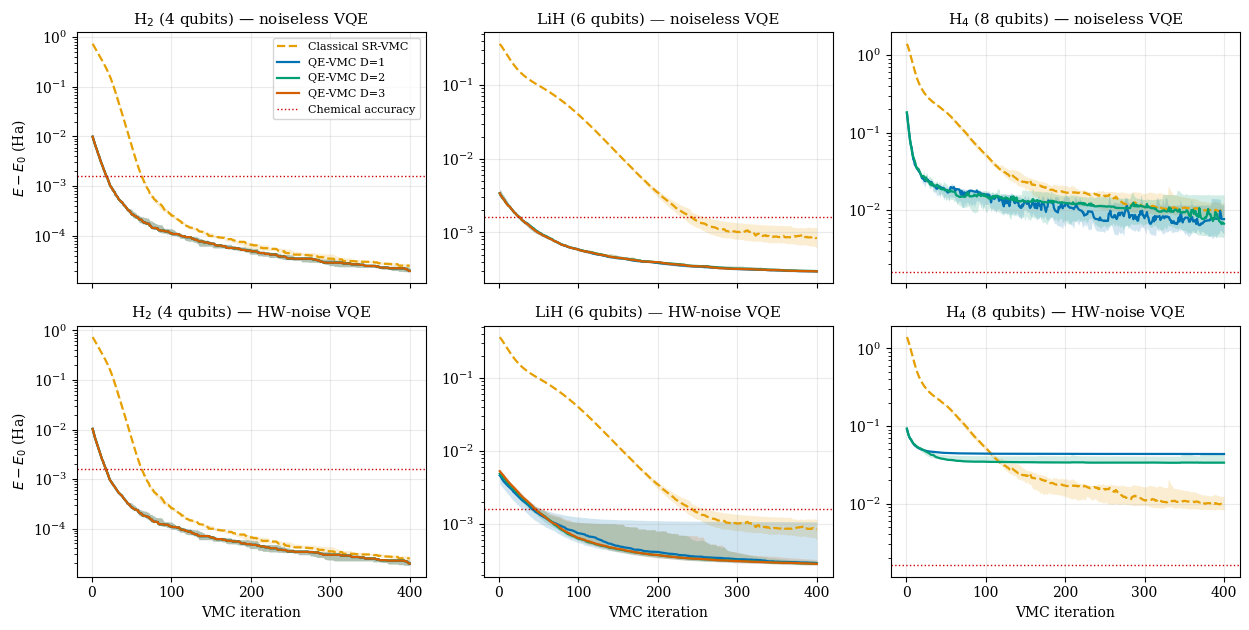

saved fig1_convergence.png


In [ ]:
D_SHOW = 2 if 2 in CIRCUIT_DEPTHS else CIRCUIT_DEPTHS[0]
fig, axes = plt.subplots(2, len(MOL_NAMES), figsize=(4.2 * len(MOL_NAMES), 6.4), sharex=True)
for j, mol in enumerate(MOL_NAMES):
    for i, noise in enumerate(["ε=0", "HW"]):
        ax = axes[i, j]
        band(ax, err_curves([(mol, "Classical SR-VMC", None, None, s) for s in SEEDS]), C["classical"], "Classical SR-VMC", "--")
        for d in CIRCUIT_DEPTHS:
            band(ax, err_curves([(mol, "QE-VMC", d, noise, s) for s in SEEDS]), C[d], f"QE-VMC D={d}")
        ax.axhline(CHEM_ACC, color=C["exact"], ls=":", lw=1, label="Chemical accuracy")
        ax.set_yscale("log")
        ax.set_title(f"{MOL_LABEL[mol]} ({PROBLEMS[mol]['n']} qubits) — {'noiseless VQE' if noise == 'ε=0' else 'HW-noise VQE'}")
        if j == 0: ax.set_ylabel(r"$E - E_0$ (Ha)")
        if i == 1: ax.set_xlabel("VMC iteration")
axes[0, 0].legend(loc="upper right")
fig.tight_layout()
save(fig, "fig1_convergence")

**Fig. 2 — Final error vs. noise.** Raw VQE, VQE + ZNE, VQE + symmetry verification, and QE-VMC (mean ± std over seeds). The orange band is classical SR-VMC.

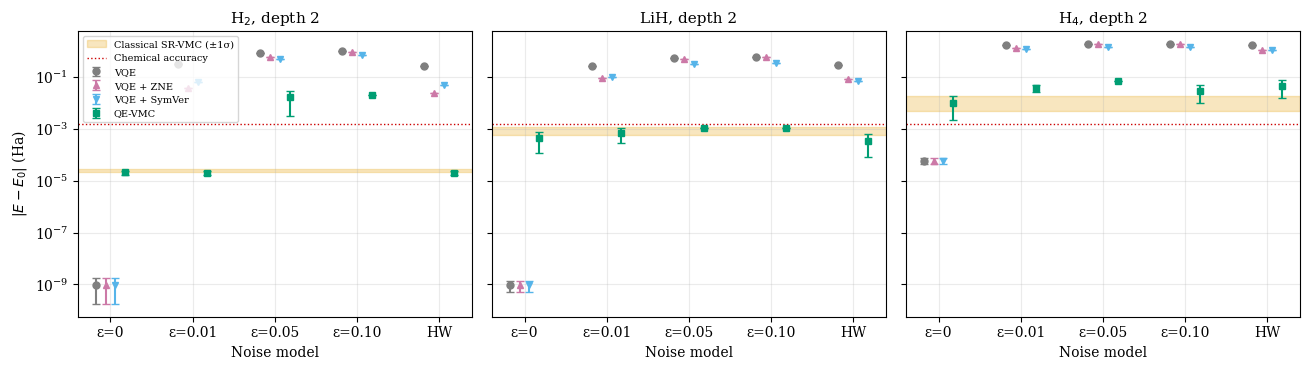

saved fig2_error_vs_noise.png


In [ ]:
fig, axes = plt.subplots(1, len(MOL_NAMES), figsize=(4.4 * len(MOL_NAMES), 3.8), sharey=True)
xs = np.arange(len(NOISE_NAMES))
for ax, mol in zip(axes, MOL_NAMES):
    m = main[(main.molecule == mol) & (main.method == "QE-VMC") & (main.depth == D_SHOW)]
    for col, lab, c, mk, off in [("dE_vqe", "VQE", C["vqe"], "o", -0.18), ("dE_zne", "VQE + ZNE", C["zne"], "^", -0.06),
                                 ("dE_sym", "VQE + SymVer", C["sym"], "v", 0.06), ("dE", "QE-VMC", C[2], "s", 0.18)]:
        g = m.assign(a=m[col].abs()).groupby("noise")["a"]
        mu = g.mean().reindex(NOISE_NAMES); sd = g.std().reindex(NOISE_NAMES)
        ax.errorbar(xs + off, mu, yerr=sd, fmt=mk, color=c, capsize=3, ms=5, label=lab)
    cl = main[(main.molecule == mol) & (main.method == "Classical SR-VMC")]["dE"].abs()
    ax.axhspan(cl.mean() - cl.std(), cl.mean() + cl.std(), color=C["classical"], alpha=0.25, label="Classical SR-VMC (±1σ)")
    ax.axhline(CHEM_ACC, color=C["exact"], ls=":", lw=1, label="Chemical accuracy")
    ax.set_yscale("log"); ax.set_xticks(xs); ax.set_xticklabels(NOISE_NAMES)
    ax.set_title(f"{MOL_LABEL[mol]}, depth {D_SHOW}"); ax.set_xlabel("Noise model")
axes[0].set_ylabel(r"$|E - E_0|$ (Ha)")
axes[0].legend(fontsize=7, loc="upper left")
fig.tight_layout()
save(fig, "fig2_error_vs_noise")

**Fig. 3 — Heatmaps.** Median QE-VMC error (mHa) per depth × noise; the number in brackets is the success rate (fraction of seeds within chemical accuracy).

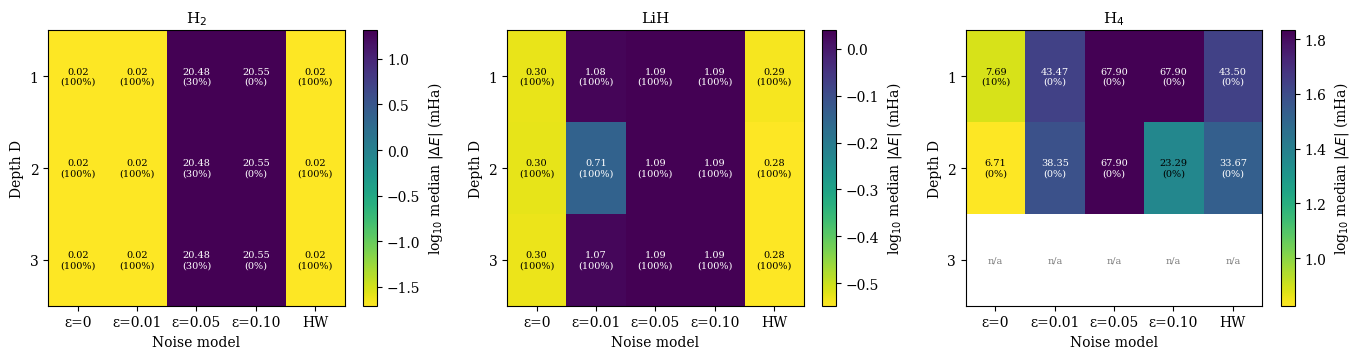

saved fig3_heatmaps.png


In [ ]:
fig, axes = plt.subplots(1, len(MOL_NAMES), figsize=(4.6 * len(MOL_NAMES), 2.2 + 0.5 * len(CIRCUIT_DEPTHS)))
for ax, mol in zip(axes, MOL_NAMES):
    s = SUMMARY_MAIN[(SUMMARY_MAIN.molecule == mol) & (SUMMARY_MAIN.method == "QE-VMC")]
    M = s.pivot(index="depth", columns="noise", values="median_dE_mHa").reindex(index=CIRCUIT_DEPTHS, columns=NOISE_NAMES)
    S = s.pivot(index="depth", columns="noise", values="success_rate").reindex(index=CIRCUIT_DEPTHS, columns=NOISE_NAMES)
    im = ax.imshow(np.log10(np.maximum(M.values, 1e-3)), cmap="viridis_r", aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            if np.isnan(M.values[i, j]):
                ax.text(j, i, "n/a", ha="center", va="center", fontsize=7, color="gray"); continue
            ax.text(j, i, f"{M.values[i, j]:.2f}\n({S.values[i, j]:.0%})", ha="center", va="center", fontsize=7,
                    color="white" if np.log10(max(M.values[i, j], 1e-3)) > np.nanmean(np.log10(np.maximum(M.values, 1e-3))) else "black")
    ax.set_xticks(range(len(NOISE_NAMES))); ax.set_xticklabels(NOISE_NAMES)
    ax.set_yticks(range(len(CIRCUIT_DEPTHS))); ax.set_yticklabels(CIRCUIT_DEPTHS)
    ax.set_xlabel("Noise model"); ax.set_ylabel("Depth D"); ax.set_title(MOL_LABEL[mol]); ax.grid(False)
    cb = fig.colorbar(im, ax=ax); cb.set_label(r"log$_{10}$ median $|\Delta E|$ (mHa)")
fig.tight_layout()
save(fig, "fig3_heatmaps")

**Fig. 4 — Ablation.** Final error per variant (box = seeds), at depth 2 with HW noise. The first group isolates the stabilisation components; the second varies only the initial state.

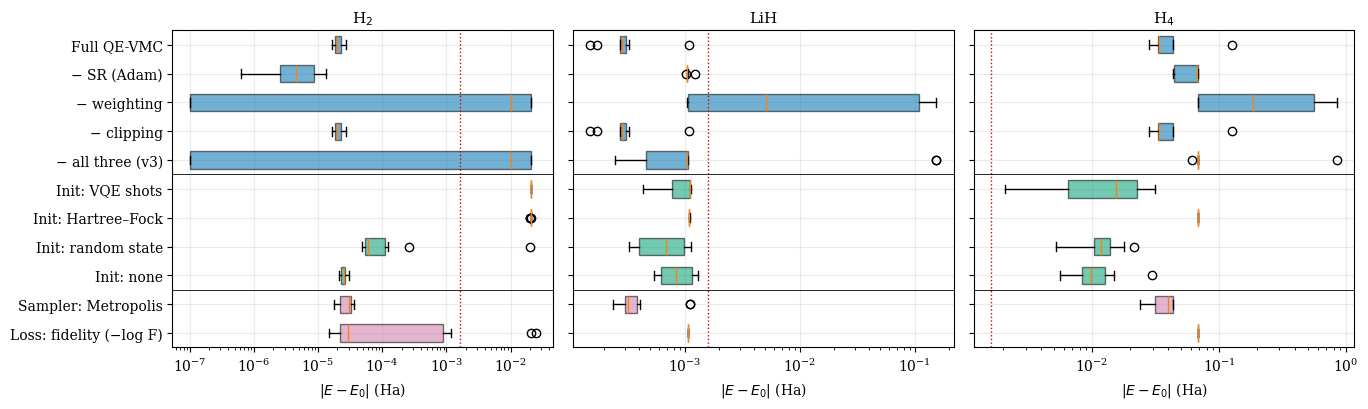

saved fig4_ablation.png


In [ ]:
abl = DF[DF.experiment == "ablation"]
names = list(ABLATIONS)
fig, axes = plt.subplots(1, len(MOL_NAMES), figsize=(4.6 * len(MOL_NAMES), 4.2), sharey=True)
for ax, mol in zip(axes, MOL_NAMES):
    data = [np.maximum(abl[(abl.molecule == mol) & (abl.method == n)]["dE"].abs().values, 1e-7) for n in names]
    bp = ax.boxplot(data, vert=False, patch_artist=True, widths=0.6, showfliers=True)
    for k, patch in enumerate(bp["boxes"]):
        patch.set_facecolor("#0072B2" if k < 5 else ("#009E73" if k < 9 else "#CC79A7")); patch.set_alpha(0.55)
    ax.axvline(CHEM_ACC, color=C["exact"], ls=":", lw=1)
    ax.axhline(5.5, color="k", lw=0.6); ax.axhline(9.5, color="k", lw=0.6)
    ax.set_xscale("log"); ax.set_title(MOL_LABEL[mol]); ax.set_xlabel(r"$|E - E_0|$ (Ha)")
axes[0].set_yticks(range(1, len(names) + 1)); axes[0].set_yticklabels(names)
axes[0].invert_yaxis()
fig.tight_layout()
save(fig, "fig4_ablation")

**Fig. 5 — Does the quantum initial state matter?** Convergence for different initial states, all with the same SR optimiser.

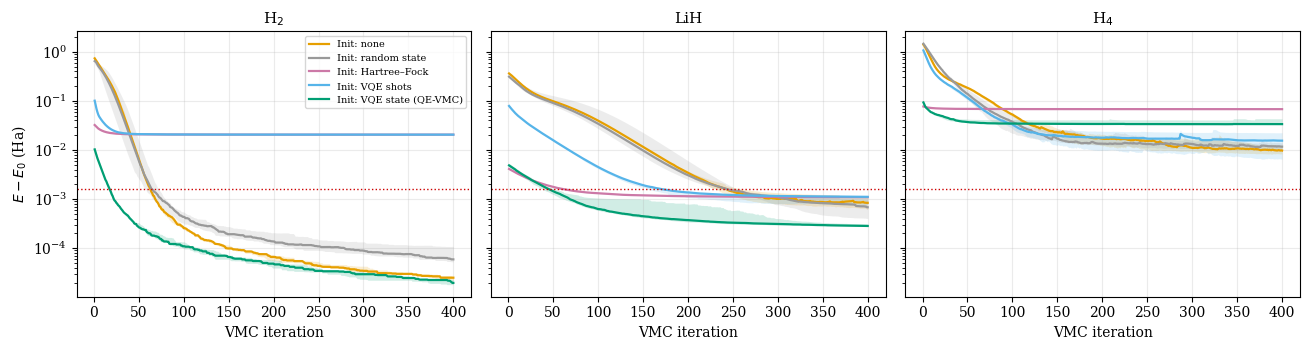

saved fig5_initialisation.png


In [ ]:
inits = ["Init: none", "Init: random state", "Init: Hartree–Fock", "Init: VQE shots", "Full QE-VMC"]
icol = ["#E69F00", "#999999", "#CC79A7", "#56B4E9", "#009E73"]
fig, axes = plt.subplots(1, len(MOL_NAMES), figsize=(4.4 * len(MOL_NAMES), 3.6), sharey=True)
for ax, mol in zip(axes, MOL_NAMES):
    for n, c in zip(inits, icol):
        band(ax, err_curves([(mol, "abl", n, ABLATION_DEPTH, ABLATION_NOISE, s) for s in SEEDS]), c,
             n.replace("Full QE-VMC", "Init: VQE state (QE-VMC)"))
    ax.axhline(CHEM_ACC, color=C["exact"], ls=":", lw=1)
    ax.set_yscale("log"); ax.set_title(MOL_LABEL[mol]); ax.set_xlabel("VMC iteration")
axes[0].set_ylabel(r"$E - E_0$ (Ha)"); axes[0].legend(fontsize=7)
fig.tight_layout()
save(fig, "fig5_initialisation")

**Fig. 6 — Comparison with classical NQS baselines.** Final error and iterations to chemical accuracy (runs that never reach it are plotted at the iteration limit).

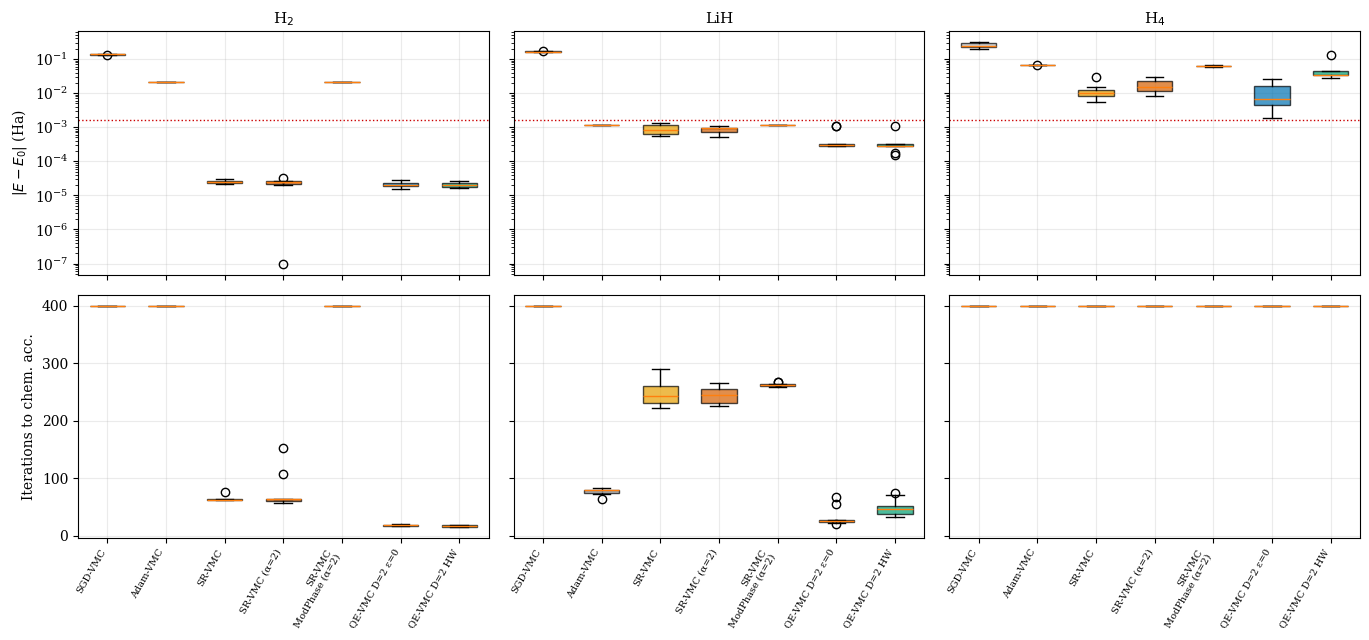

saved fig6_baselines.png


In [ ]:
methods = ["Classical SGD-VMC", "Classical Adam-VMC", "Classical SR-VMC", "Classical SR-VMC (α=2)",
           "Classical SR-VMC ModPhase (α=2)", f"QE-VMC D={D_SHOW} ε=0", f"QE-VMC D={D_SHOW} HW"]


def _select(mol, meth):
    if meth.startswith("QE-VMC"):
        noise = "ε=0" if meth.endswith("ε=0") else "HW"
        return main[(main.molecule == mol) & (main.method == "QE-VMC") & (main.depth == D_SHOW) & (main.noise == noise)]
    return DF[(DF.molecule == mol) & (DF.method == meth)]


fig, axes = plt.subplots(2, len(MOL_NAMES), figsize=(4.6 * len(MOL_NAMES), 6.5), sharey="row")
cols = ["#bbbbbb", "#999999", C["classical"], "#D55E00", "#8c564b", C[1], C[2]]
for j, mol in enumerate(MOL_NAMES):
    d1 = [np.maximum(_select(mol, m)["dE"].abs().values, 1e-7) for m in methods]
    d2 = [_select(mol, m)["it_ca"].fillna(VMC_ITERS).values for m in methods]
    for i, data in enumerate([d1, d2]):
        ax = axes[i, j]
        bp = ax.boxplot(data, patch_artist=True, widths=0.6)
        for p, c in zip(bp["boxes"], cols):
            p.set_facecolor(c); p.set_alpha(0.7)
        ax.set_xticks(range(1, len(methods) + 1))
        ax.set_xticklabels([m.replace("Classical ", "").replace(" ModPhase", "\nModPhase") for m in methods],
                           rotation=60, ha="right", fontsize=7)
        if i == 0:
            ax.set_yscale("log"); ax.axhline(CHEM_ACC, color=C["exact"], ls=":", lw=1)
            ax.set_title(MOL_LABEL[mol]); ax.set_xticklabels([])
    axes[0, 0].set_ylabel(r"$|E - E_0|$ (Ha)"); axes[1, 0].set_ylabel("Iterations to chem. acc.")
fig.tight_layout()
save(fig, "fig6_baselines")

**Fig. 7 — Cost-to-accuracy, overhead included.** (a) Median error vs. cumulative wall-clock time; the QE-VMC curves are shifted right by the measured VQE + pretraining time. (b) Hardware budget of the VQE stage (parameter-shift circuit executions × QWC groups × shots) compared with VMC samples.

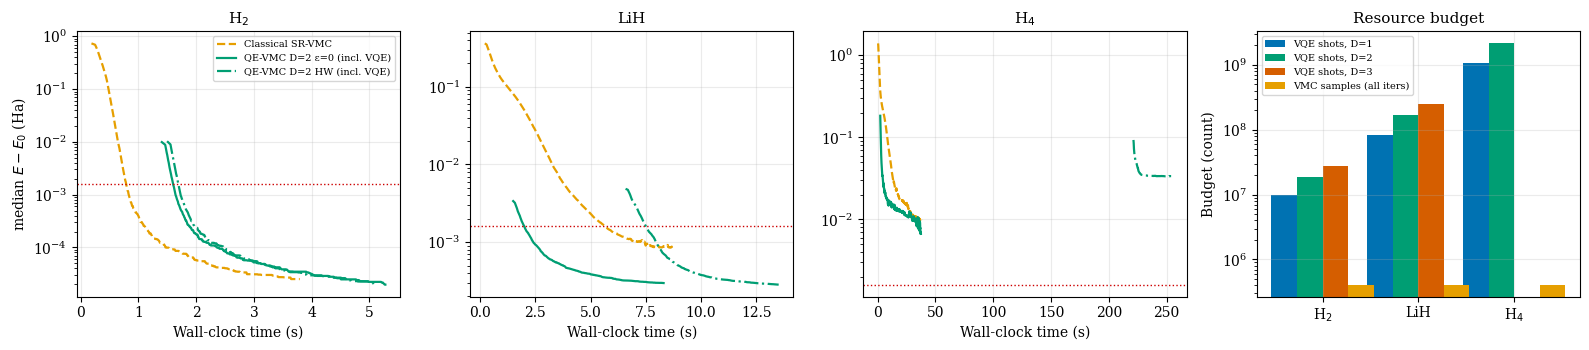

saved fig7_cost_to_accuracy.png


In [ ]:
fig, axes = plt.subplots(1, len(MOL_NAMES) + 1, figsize=(4.0 * (len(MOL_NAMES) + 1), 3.6))
for ax, mol in zip(axes[:-1], MOL_NAMES):
    def curve(keys, offset):                       # median over seeds, per iteration
        cs = [(HISTS[k]["time_hist"] + o, np.maximum(HISTS[k]["exact_hist"] - PROBLEMS[mol]["E0"], 1e-7))
              for k, o in zip(keys, offset) if k in HISTS]
        if not cs: return None
        L = min(len(c[0]) for c in cs)
        return np.median([c[0][:L] for c in cs], 0), np.median([c[1][:L] for c in cs], 0)
    cl_keys = [(mol, "Classical SR-VMC", None, None, s) for s in SEEDS]
    r = curve(cl_keys, [0] * len(SEEDS))
    if r: ax.plot(*r, color=C["classical"], ls="--", lw=1.6, label="Classical SR-VMC")
    for noise, ls in [("ε=0", "-"), ("HW", "-.")]:
        sub = main[(main.molecule == mol) & (main.method == "QE-VMC") & (main.depth == D_SHOW) & (main.noise == noise)].set_index("seed")
        keys = [(mol, "QE-VMC", D_SHOW, noise, s) for s in SEEDS]
        offs = [sub.loc[s, "vqe_time"] + sub.loc[s, "pretrain_time"] if s in sub.index else 0 for s in SEEDS]
        r = curve(keys, offs)
        if r: ax.plot(*r, color=C[2], ls=ls, lw=1.6, label=f"QE-VMC D={D_SHOW} {noise} (incl. VQE)")
    ax.axhline(CHEM_ACC, color=C["exact"], ls=":", lw=1)
    ax.set_yscale("log"); ax.set_xlabel("Wall-clock time (s)"); ax.set_title(MOL_LABEL[mol])
axes[0].set_ylabel(r"median $E - E_0$ (Ha)"); axes[0].legend(fontsize=7)

ax = axes[-1]
qv = main[(main.method == "QE-VMC") & (main.noise == "HW")].groupby(["molecule", "depth"])["shots_est"].mean()
w = 0.8 / len(CIRCUIT_DEPTHS)
for k, d in enumerate(CIRCUIT_DEPTHS):
    ax.bar(np.arange(len(MOL_NAMES)) + k * w, [qv.get((m, d), np.nan) for m in MOL_NAMES], w, color=C[d], label=f"VQE shots, D={d}")
ax.bar(np.arange(len(MOL_NAMES)) + len(CIRCUIT_DEPTHS) * w, [VMC_ITERS * VMC_SAMPLES] * len(MOL_NAMES), w,
       color=C["classical"], label="VMC samples (all iters)")
ax.set_yscale("log"); ax.set_xticks(np.arange(len(MOL_NAMES)) + 0.4); ax.set_xticklabels([MOL_LABEL[m] for m in MOL_NAMES])
ax.set_ylabel("Budget (count)"); ax.set_title("Resource budget"); ax.legend(fontsize=7)
fig.tight_layout()
save(fig, "fig7_cost_to_accuracy")

**Fig. 8 — Failure analysis.** Each QE-VMC run of the main sweep: final error vs. pretraining fidelity, vs. how concentrated the final RBM is on a single configuration, and vs. the energy right after pretraining. Red = catastrophic (ΔE > 100 mHa), orange = > 10 mHa. The table lists every run above 10 mHa.

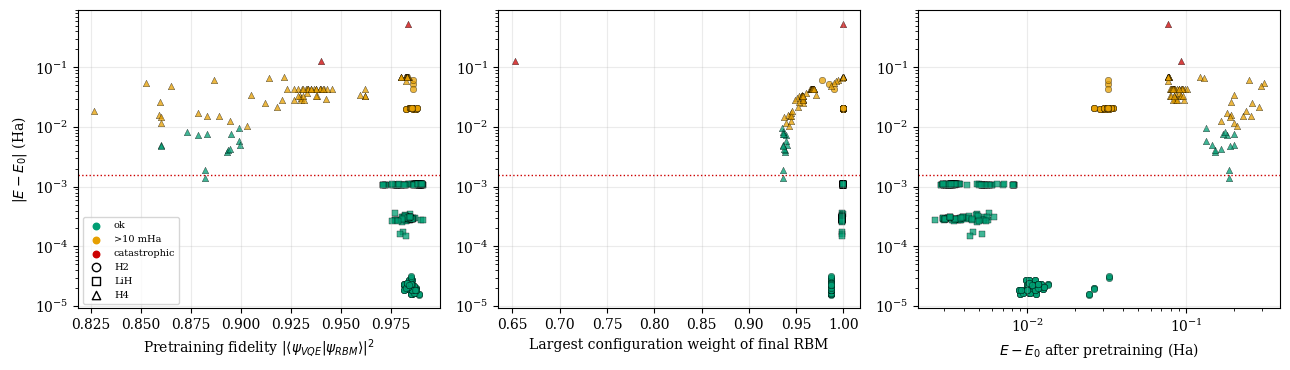

saved fig8_failure_analysis.png
137 of 400 QE-VMC runs above 10 mHa; 2 catastrophic.


,molecule,depth,noise,seed,dE,E_init,pretrain_fidelity,max_w_before_clip,overlap_gs,p_max_config,n_unique_samples,var_final
390,H4,1.0,ε=0.10,6,0.541793,-2.089600,0.983657,0.295292,0.936485,0.999993,1,1.793662e-43
418,H4,2.0,HW,8,0.127049,-2.073579,0.940271,0.950983,0.969251,0.652243,15,2.122822e-02
427,H4,2.0,ε=0.05,9,0.067911,-2.089146,0.982863,0.281174,0.936861,0.999826,2,8.292307e-06
422,H4,1.0,ε=0.05,9,0.067911,-2.089148,0.982861,0.281169,0.936871,0.999826,2,8.292616e-06
423,H4,1.0,ε=0.10,9,0.067908,-2.089358,0.983194,0.280971,0.936479,0.999794,3,1.324614e-05
389,H4,1.0,ε=0.05,6,0.067907,-2.089316,0.983204,0.294739,0.936874,0.999832,3,2.328935e-05
394,H4,2.0,ε=0.05,6,0.067906,-2.089309,0.983192,0.294749,0.936868,0.999833,3,2.294873e-05
335,H4,1.0,ε=0.10,1,0.067904,-2.089475,0.982676,0.286818,0.936477,0.999832,6,3.893995e-05
361,H4,2.0,ε=0.05,3,0.067904,-2.089254,0.983448,0.303767,0.936870,0.999836,2,7.862263e-06
356,H4,1.0,ε=0.05,3,0.067904,-2.089256,0.983454,0.303777,0.936865,0.999836,2,7.862537e-06


In [ ]:
q = main[main.method == "QE-VMC"].copy()
q["absdE"] = q["dE"].abs().clip(lower=1e-7)
q["Einit_err"] = (q["E_init"] - q["molecule"].map({m: PROBLEMS[m]["E0"] for m in MOL_NAMES})).clip(lower=1e-7)
q["cls"] = np.where(q["dE"] > CATASTROPHIC, "catastrophic", np.where(q["absdE"] > LOOSE_THR, ">10 mHa", "ok"))
cmap = {"ok": "#009E73", ">10 mHa": "#E69F00", "catastrophic": "#CC0000"}
mk = {"H2": "o", "LiH": "s", "H4": "^"}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for (mol, cls), g in q.groupby(["molecule", "cls"]):
    for ax, x in zip(axes, ["pretrain_fidelity", "p_max_config", "Einit_err"]):
        ax.scatter(g[x], g["absdE"], c=cmap[cls], marker=mk.get(mol, "o"), s=22, alpha=0.75, edgecolor="k", lw=0.3)
for ax, lab in zip(axes, ["Pretraining fidelity $|\\langle\\psi_{VQE}|\\psi_{RBM}\\rangle|^2$",
                          "Largest configuration weight of final RBM", r"$E - E_0$ after pretraining (Ha)"]):
    ax.set_yscale("log"); ax.set_xlabel(lab); ax.axhline(CHEM_ACC, color=C["exact"], ls=":", lw=1)
axes[2].set_xscale("log")
axes[0].set_ylabel(r"$|E - E_0|$ (Ha)")
for c, col in cmap.items():
    axes[0].scatter([], [], c=col, label=c, s=22)
for m, s in mk.items():
    axes[0].scatter([], [], c="w", edgecolor="k", marker=s, label=m)
axes[0].legend(fontsize=7)
fig.tight_layout()
save(fig, "fig8_failure_analysis")

fails = q[q.cls != "ok"][["molecule", "depth", "noise", "seed", "dE", "E_init", "pretrain_fidelity",
                          "max_w_before_clip", "overlap_gs", "p_max_config", "n_unique_samples", "var_final"]]
fails.to_csv(os.path.join(TAB_DIR, "failed_runs.csv"), index=False)
print(f"{len(fails)} of {len(q)} QE-VMC runs above 10 mHa; "
      f"{(q.cls == 'catastrophic').sum()} catastrophic.")
display(fails.sort_values("dE", ascending=False).head(15))

**Fig. 9 — Scaling with system size.** Mean final error (± std) and VMC wall-clock time versus qubit count, noiseless and HW-noise QE-VMC vs. classical SR-VMC.

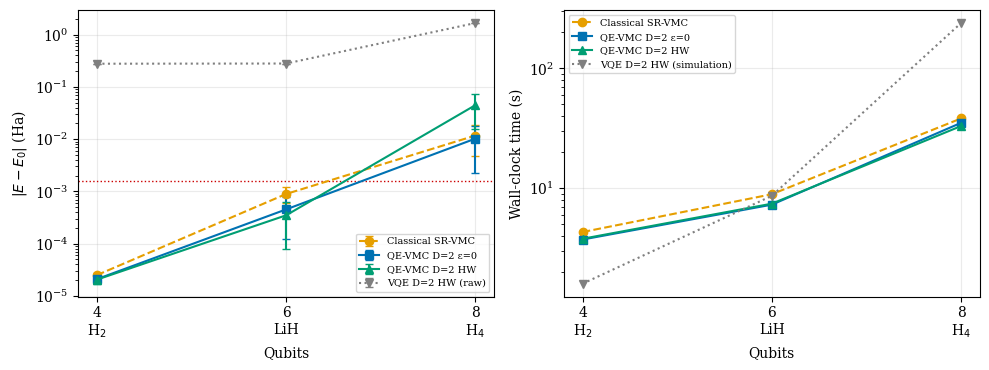

saved fig9_scaling.png


In [ ]:
nq = [PROBLEMS[m]["n"] for m in MOL_NAMES]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.8))
series = [("Classical SR-VMC", main[main.method == "Classical SR-VMC"], C["classical"], "--o"),
          (f"QE-VMC D={D_SHOW} ε=0", main[(main.method == "QE-VMC") & (main.depth == D_SHOW) & (main.noise == "ε=0")], C[1], "-s"),
          (f"QE-VMC D={D_SHOW} HW", main[(main.method == "QE-VMC") & (main.depth == D_SHOW) & (main.noise == "HW")], C[2], "-^"),
          (f"VQE D={D_SHOW} HW (raw)", main[(main.method == "QE-VMC") & (main.depth == D_SHOW) & (main.noise == "HW")].assign(dE=lambda d: d.dE_vqe), C["vqe"], ":v")]
for lab, d, c, st in series:
    g = d.assign(a=d.dE.abs()).groupby("molecule")["a"]
    a1.errorbar(nq, g.mean().reindex(MOL_NAMES), yerr=g.std().reindex(MOL_NAMES), fmt=st, color=c, capsize=3, label=lab)
    if not lab.startswith("VQE"):
        t = d.groupby("molecule")["vmc_time"].mean().reindex(MOL_NAMES)
        a2.plot(nq, t, st, color=c, label=lab)
vt = main[(main.method == "QE-VMC") & (main.depth == D_SHOW) & (main.noise == "HW")].groupby("molecule")["vqe_time"].mean().reindex(MOL_NAMES)
a2.plot(nq, vt, ":v", color=C["vqe"], label=f"VQE D={D_SHOW} HW (simulation)")
a1.axhline(CHEM_ACC, color=C["exact"], ls=":", lw=1)
a1.set_yscale("log"); a1.set_xlabel("Qubits"); a1.set_ylabel(r"$|E - E_0|$ (Ha)"); a1.set_xticks(nq)
a2.set_yscale("log"); a2.set_xlabel("Qubits"); a2.set_ylabel("Wall-clock time (s)"); a2.set_xticks(nq)
a1.set_xticklabels([f"{n}\n{MOL_LABEL[m]}" for n, m in zip(nq, MOL_NAMES)])
a2.set_xticklabels([f"{n}\n{MOL_LABEL[m]}" for n, m in zip(nq, MOL_NAMES)])
a1.legend(fontsize=7); a2.legend(fontsize=7)
fig.tight_layout()
save(fig, "fig9_scaling")

**Fig. 10 — H₂ dissociation curve.** Mean over seeds; the inset panel shows the error relative to the exact energy.

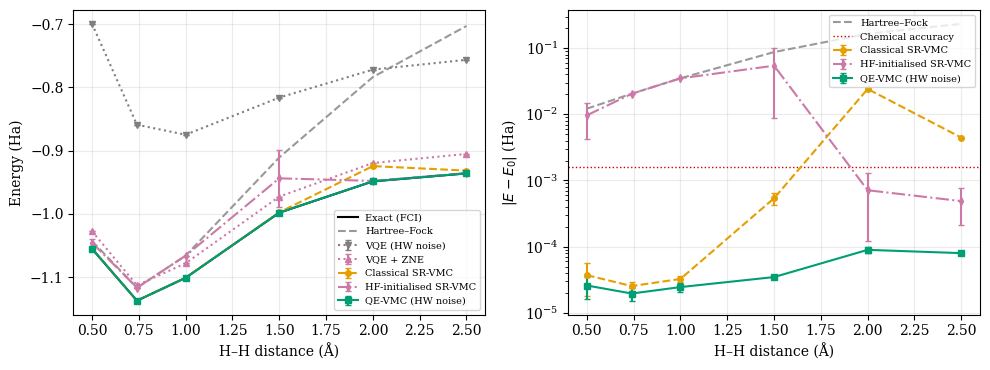

saved fig10_dissociation.png


In [ ]:
if len(DISS):
    g = DISS.groupby("R").agg(["mean", "std"])
    R = g.index.values
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.8))
    a1.plot(R, g[("E0", "mean")], "k-", lw=1.5, label="Exact (FCI)")
    a1.plot(R, g[("E_HF", "mean")], color="#999999", ls="--", label="Hartree–Fock")
    for col, lab, c, st in [("E_vqe", "VQE (HW noise)", C["vqe"], "v:"), ("E_zne", "VQE + ZNE", C["zne"], "^:"),
                            ("E_classical", "Classical SR-VMC", C["classical"], "o--"),
                            ("E_hfinit", "HF-initialised SR-VMC", "#CC79A7", "d-."),
                            ("E_qevmc", "QE-VMC (HW noise)", C[2], "s-")]:
        a1.errorbar(R, g[(col, "mean")], yerr=g[(col, "std")], fmt=st, color=c, capsize=2, ms=4, label=lab)
        if col not in ("E_vqe", "E_zne"):
            e = (DISS[col] - DISS["E0"]).abs().groupby(DISS["R"])
            a2.errorbar(R, e.mean(), yerr=e.std(), fmt=st, color=c, capsize=2, ms=4, label=lab)
    e = (DISS["E_HF"] - DISS["E0"]).groupby(DISS["R"]).mean()
    a2.plot(R, e, color="#999999", ls="--", label="Hartree–Fock")
    a2.axhline(CHEM_ACC, color=C["exact"], ls=":", lw=1, label="Chemical accuracy")
    a1.set_xlabel("H–H distance (Å)"); a1.set_ylabel("Energy (Ha)"); a1.legend(fontsize=7)
    a2.set_xlabel("H–H distance (Å)"); a2.set_ylabel(r"$|E - E_0|$ (Ha)"); a2.set_yscale("log"); a2.legend(fontsize=7)
    fig.tight_layout()
    save(fig, "fig10_dissociation")

**Fig. 11 — VQE optimisation curves** (median over seeds, depth × noise, all molecules).

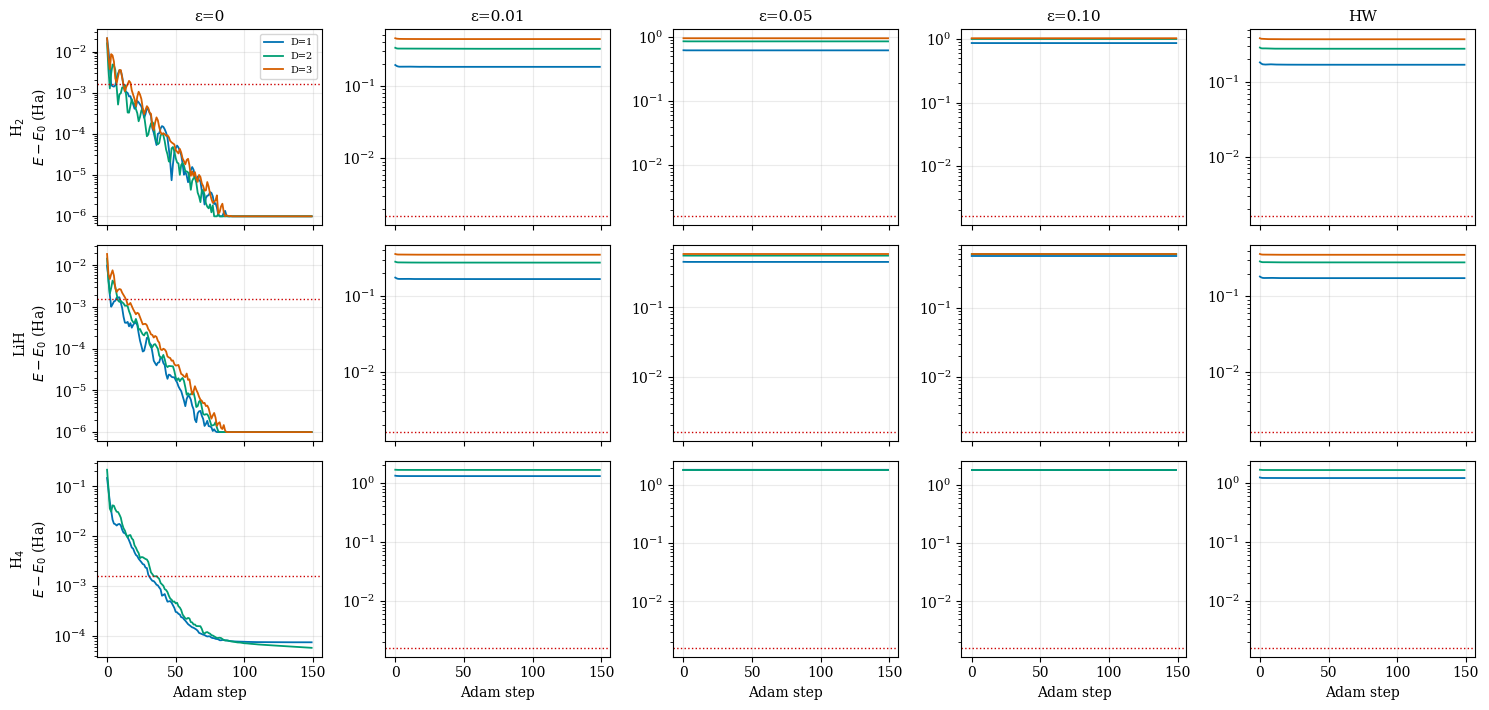

saved fig11_vqe_curves.png


In [ ]:
fig, axes = plt.subplots(len(MOL_NAMES), len(NOISE_NAMES), figsize=(3.0 * len(NOISE_NAMES), 2.4 * len(MOL_NAMES)), sharex=True)
for i, mol in enumerate(MOL_NAMES):
    for j, noise in enumerate(NOISE_NAMES):
        ax = axes[i, j]
        for d in CIRCUIT_DEPTHS:
            hs = np.array([HISTS[(mol, "VQE", d, noise, s)] for s in SEEDS if (mol, "VQE", d, noise, s) in HISTS])
            if len(hs):
                e = np.maximum(hs - PROBLEMS[mol]["E0"], 1e-6)
                ax.plot(np.median(e, 0), color=C[d], lw=1.3, label=f"D={d}")
        ax.axhline(CHEM_ACC, color=C["exact"], ls=":", lw=1)
        ax.set_yscale("log")
        if i == 0: ax.set_title(noise)
        if j == 0: ax.set_ylabel(f"{MOL_LABEL[mol]}\n$E - E_0$ (Ha)")
        if i == len(MOL_NAMES) - 1: ax.set_xlabel("Adam step")
axes[0, 0].legend(fontsize=7)
fig.tight_layout()
save(fig, "fig11_vqe_curves")

## 13. Key numbers for the manuscript
A compact summary printed and saved to `results/key_results.json`. Send this file together with the `results/tables/` folder for the paper update.

In [ ]:
key = {"molecules": mol_table.to_dict(orient="records"), "config": CONFIG, "per_molecule": {}}
for mol in MOL_NAMES:
    m = main[main.molecule == mol]
    cl = m[m.method == "Classical SR-VMC"]
    d = {"classical_SR": dict(mean_dE_mHa=1e3 * cl.dE.abs().mean(), std_dE_mHa=1e3 * cl.dE.abs().std(),
                              success_rate=float((cl.dE.abs() <= CHEM_ACC).mean()),
                              mean_iters_to_CA=float(cl.it_ca.mean()))}
    for depth in depths_for(mol):
        for noise in NOISE_NAMES:
            s = m[(m.depth == depth) & (m.noise == noise)]
            d[f"QE-VMC D={depth} {noise}"] = dict(
                mean_dE_mHa=1e3 * s.dE.abs().mean(), std_dE_mHa=1e3 * s.dE.abs().std(),
                success_rate=float((s.dE.abs() <= CHEM_ACC).mean()),
                catastrophic=int((s.dE > CATASTROPHIC).sum()),
                mean_iters_to_CA=float(s.it_ca.mean()),
                VQE_mHa=1e3 * s.dE_vqe.abs().mean(), ZNE_mHa=1e3 * s.dE_zne.abs().mean(),
                SymVer_mHa=1e3 * s.dE_sym.abs().mean(), vqe_time_s=float(s.vqe_time.mean()))
    key["per_molecule"][mol] = d
key["ablation"] = SUMMARY_ABL.to_dict(orient="records")
key["baselines"] = SUMMARY_BASE.to_dict(orient="records")
key["tests"] = TESTS.to_dict(orient="records")
if len(DISS):
    key["dissociation"] = DISS.groupby("R").mean().reset_index().to_dict(orient="records")

env = {"python": platform.python_version(), "platform": platform.platform(), "numpy": np.__version__,
       "jax": jax.__version__, "netket": nk.__version__, "pennylane": qml.__version__,
       "pandas": pd.__version__, "scipy": __import__("scipy").__version__}
key["environment"] = env
with open(os.path.join(RESULTS_DIR, "key_results.json"), "w") as f:
    json.dump(key, f, indent=1, default=lambda o: None if (isinstance(o, float) and np.isnan(o)) else str(o))

for mol in MOL_NAMES:
    print(f"\n{mol}:  E_exact = {PROBLEMS[mol]['E0']:.6f} Ha,  E_HF = {PROBLEMS[mol]['E_HF']:.6f} Ha")
    for k, v in key["per_molecule"][mol].items():
        print(f"  {k:28s} |ΔE| = {v['mean_dE_mHa']:8.3f} ± {v['std_dE_mHa']:7.3f} mHa   "
              f"success = {v['success_rate']:.0%}   iters→CA = {v['mean_iters_to_CA']:.0f}")
print("\nEnvironment:", env)


H2:  E_exact = -1.137284 Ha,  E_HF = -1.116759 Ha
  classical_SR                 |ΔE| =    0.025 ±   0.003 mHa   success = 100%   iters→CA = 65
  QE-VMC D=1 ε=0               |ΔE| =    0.021 ±   0.004 mHa   success = 100%   iters→CA = 18
  QE-VMC D=1 ε=0.01            |ΔE| =    0.021 ±   0.004 mHa   success = 100%   iters→CA = 18
  QE-VMC D=1 ε=0.05            |ΔE| =   17.529 ±  15.495 mHa   success = 30%   iters→CA = 72
  QE-VMC D=1 ε=0.10            |ΔE| =   20.513 ±   0.165 mHa   success = 0%   iters→CA = nan
  QE-VMC D=1 HW                |ΔE| =    0.020 ±   0.003 mHa   success = 100%   iters→CA = 18
  QE-VMC D=2 ε=0               |ΔE| =    0.021 ±   0.004 mHa   success = 100%   iters→CA = 18
  QE-VMC D=2 ε=0.01            |ΔE| =    0.021 ±   0.004 mHa   success = 100%   iters→CA = 18
  QE-VMC D=2 ε=0.05            |ΔE| =   16.666 ±  13.472 mHa   success = 30%   iters→CA = 72
  QE-VMC D=2 ε=0.10            |ΔE| =   20.513 ±   0.165 mHa   success = 0%   iters→CA = nan
  QE-VMC D=2 

## 14. Package the results
Creates `results.zip` with all figures (PNG), tables (CSV + LaTeX), raw run data and the configuration.

In [ ]:
import shutil
shutil.make_archive("results", "zip", RESULTS_DIR)
print("Wrote results.zip:", round(os.path.getsize("results.zip") / 1e6, 1), "MB")

Wrote results.zip: 8.8 MB
